# Case Study 16 — "Biriyani, Biryani, Beriani": Dish Search, Query Understanding and Ranking Metrics (NDCG, MRR) at Swiggy

**Priority:** ★★ Good to have · **Reference:** Case Study 16 — *Swiggy: dish search and query understanding* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Search and Discovery, Product (search, restaurant listing), Growth, Finance
**Data:** ⚠️ **SYNTHETIC** (D-16-01). Swiggy's search logs, taxonomy and relevance labels are confidential; this is a calibrated simulation with hidden graded relevance and a hidden click model.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs16_dish_search_ranking.ipynb`

## 0. Executive Summary for Business

*(Synthetic search sessions with hidden graded relevance and a hidden click model, built on the documented design of Swiggy's dish search: fuzzy text matching in production, character-trigram embeddings and a learning-to-rank model. Swiggy's data, models and result tables are not reproduced; no online lift is published. This is an interview-standard solution on simulated data. Written after the analysis.)*

- **The question:** how do we return the right dish when the spelling is non-standard, the query is vague or the dish is not available nearby, and how do we prove a new ranker is better?
- **Fuzzy word matching leaves a lot on the table.** On the test week (5,548 sessions) the production-like baseline reaches **NDCG@10 of 0.776** (95% CI 0.766 to 0.786) and returns **nothing for 10.8% of searches**. Exact word matching is worse (0.673, 20.2% empty).
- **Character-level methods fix misspellings.** For misspelled dish queries NDCG@10 is 0.698 for fuzzy matching, **0.790 for character trigrams** and **0.890 for the learned query classifier**. For clean queries all are about 0.92. The gain is concentrated where spelling is wrong (difference-in-differences +0.195, CI 0.168 to 0.222 for the classifier). Fuzzy matching degrades with each extra edit (3 or more edits: 0.458); the classifier holds at 0.863.
- **The best system is a learned ranker on top.** Learning to rank on clicks reaches **NDCG@10 of 0.900** (CI 0.894 to 0.907), **+0.124 over production** (paired CI 0.116 to 0.133, Holm p < 1e-4), and removes empty results. The simple blend of the three text scores is close (0.893); the ranker adds only +0.007 over it (CI 0.003 to 0.011), so query understanding matters more than the extra ranking features.
- **Click logs are usable but biased.** For the same relevance the odds of a click at position 10 are about 0.14 of those at position 1. Training on production logs only gives 0.896 against 0.900 with the n-gram trial arm included, and inverse-propensity weighting gives 0.896: small differences here. The offline click-replay metric ranks the methods the **wrong way** (Spearman with editorial NDCG -0.31, with the online twin -0.52; neither significant with 8 methods), because it favours whatever system produced the logs.
- **Unavailable dishes need alternatives.** For 21% of dish-like sessions the dish is not in the area. Fuzzy matching scores 0.505 there, the learned classifier **0.975** and the ranker 0.860. Vague queries stay hard (0.598 for the ranker).
- **Embeddings:** character trigrams cluster dish families much better than word-level embeddings (Davies-Bouldin 0.36 vs 0.89); 66.7% of sampled misspelled queries have no known word.
- **Money (assumed, no Swiggy figure published):** a base case of about **₹55 crore a year** for the ranker (worst ₹25 crore, best ₹88 crore), about **₹20 crore** for the blend, after a ₹4 crore running cost. The twin's click model also rewards rating and distance, so treat these as an upper-leaning order of magnitude.
- **Evaluation size:** to detect a 0.01 NDCG difference between two systems we need about **8,850 judged sessions**; our test set can detect 0.013.
- **I recommend:** ship character-level retrieval plus the learned query classifier first (the blend), add the click-trained ranker behind an A/B test with a 10% exploration arm, keep a refreshed spelling dictionary, and do not use click replay as the decision metric.

## 1. The Problem in Simple English

Search is where the hungriest customers start. They type a dish, not a restaurant. But Indian dish names have **no standard English spelling**: *biryani* is typed as *biriyani*, *biriani*, *beriani* or *briyani*. A system that matches words exactly returns **nothing**, and even a system that tolerates one or two typing errors can miss a transliteration. Some dishes are also **not available nearby**, and then the customer should see the closest alternatives instead of an empty page. Newer queries are vaguer ("tiffin", "something sweet", "biryani near me under 200").

Leaders and interviewers want to know:
1. How much better is a **character-level, learned** approach than the **fuzzy word matching** we have today, and **for whom** (clean vs misspelled, plain vs vague queries)?
2. Which **ranking metrics** should we trust (**NDCG**, **MRR**, precision at 1), and how many queries do we need to judge a difference?
3. Can we train a **ranker on click logs**, given that clicks are biased by **position** and by **what the old system chose to show**?
4. Does an **offline** win predict an **online** win?
5. What is a fix worth in ₹, and what should we ship first?

## 2. Reference from the Case File

### (a) What Swiggy did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Dish names have no standard English spelling; text matching can return no results; some searched dishes are unavailable locally and nothing similar is shown; later posts add multi-intent queries (dish, diet, mood, time slot) |
| Data (as reported) | About 2M query–ordered-dish tuples over 2 months for embedding training; 35,000 query–clicked-dish pairs for validation V1 and 26,000 for a misspelled set V2 built from a curated spelling-variation dictionary; one month of click logs for ranking, validated on a week from a much later period; a food taxonomy of 300+ dish families and 6 categories |
| Approach (2021) | Siamese network with a **custom character-trigram tokenizer** and triplet loss to embed queries and dishes; the cosine similarity is used as a feature in a **learning-to-rank** model. A word-piece transformer was rejected because misspellings break tokenization and it was slow. Ranking: retrieval cuts millions of dishes to hundreds, then a deep model scores semantic, restaurant, popularity and distance-time inputs, trained on **clicked > shown-but-not-clicked > random** negatives |
| Approach (2024) | Two-stage fine-tuned small language model for embedding retrieval of complex queries, tested on a small cohort |
| Metrics reported | MRR, Recall@100 (embeddings), MAP, Precision@1, Precision@5 (2024); the character-trigram model improves on a FastText baseline by 3% (MRR) and 4.49% (Recall@100) on V1 and by 93% and 25% on the misspelled V2; Word2Vec could not embed about 32% of available dishes in the test city; Davies-Bouldin index used to check that embeddings cluster by dish family |
| Evidence limits | Most result tables are images (values not disclosed). **No online conversion or revenue lift is published** (ND). Public method detail is thin for the ranking model |

**Source:** Swiggy Bytes, "Find My Food" (2021-03-27), "Using Deep Learning for Ranking in Dish Search" (2021-07-20), "Improving search relevance in hyperlocal food delivery using (small) language models" (2024-03-13, CODS-COMAD 2024), read through a proxy.

**Plain statement of limits:** the public posts describe the ideas and a few relative numbers, not the full system. This notebook is an **interview-standard solution on simulated data**, not a reproduction of Swiggy's model. We do not train a deep Siamese network; we use character n-gram features with a linear classifier and gradient boosting, in the same spirit.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 120 dish families (30 clusters of 4, in 6 categories), 1,200 menu names, 700 restaurants and 19,600 listings in 5 delivery areas, about 48,000 search sessions over 60 days. 31% of sessions misspelled; some dishes unavailable in some areas; four query types (plain dish, dish + modifier, vague cluster word, multi-intent); hidden graded relevance 0 to 3 and a hidden click model with position bias |
| Methods compared | (1) exact word match; (2) **fuzzy word match** (an ElasticSearch-style baseline and our "production"); (3) **character-trigram cosine**; (4) **learned query classifier** (query to dish family, trained on ordered dishes plus a spelling dictionary); (5) a heuristic blend; (6) **learning to rank** on clicks (gradient boosting); (7) the same with inverse-propensity weights; (8) the same trained only on production logs (selection-bias check) |
| Statistics added | NDCG@k, MRR, precision@1 with bootstrap CIs; **paired Wilcoxon and bootstrap** tests with Holm; **difference-in-differences** for misspelled vs clean; edit-distance trend; heterogeneity by query type and availability; **Davies-Bouldin** embedding check and out-of-vocabulary rate; position-bias and click-label noise; **offline replay vs editorial vs online twin** (Spearman); evaluation-set size and **A/B sample size** |

### (c) How the industry uses this

Every Indian food and grocery app runs the same stack: **query understanding** (spell and transliteration handling, intent classification), **retrieval** (text plus embeddings), and a **ranker** that combines relevance with rating, delivery time, price and popularity. Teams evaluate with **NDCG, MRR and precision@k** on human-labelled sets and confirm online with search conversion, null-result rate and orders per search. Interview questions: why NDCG over accuracy, how to build a test set for misspellings, position bias in click data, and how to ship a ranker safely.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How do we make dish search return the right dish, even when it is misspelled, vague or locally unavailable, and prove it before we ship? |
| Analytical | Which retrieval and ranking method gives the best graded relevance, for which queries, how many judged queries do we need, and can click logs train a ranker without inheriting the old system's blind spots? |

**Hypotheses**
- **H1:** H0: the fuzzy word-match baseline and the best alternative have equal mean NDCG@10 on the same sessions (paired Wilcoxon and bootstrap; Holm across comparisons).
- **H2 (misspellings):** H0: the gain of the learned/character-level approach over fuzzy word match is the same for clean and misspelled queries (difference-in-differences with bootstrap CI).
- **H3 (learning to rank):** H0: a ranker trained on clicks has the same NDCG@10 as the best text-only method; and H0: weighting by inverse propensity, or training only on production logs, changes nothing.
- **H4 (embeddings):** H0: character-trigram embeddings cluster dish families no better than word-level embeddings (Davies-Bouldin).
- **H5 (metrics):** H0: the offline click-replay ranking of methods equals their editorial-NDCG ranking and their online (twin) ranking (Spearman).

**Primary metric:** **NDCG@10** with gain 2^rel − 1 and graded editorial relevance 0 to 3 (the hidden truth). **Secondary:** **MRR@10** and **precision@1** (answerable queries), **zero-result rate**, NDCG@1/3/5. **Online proxy:** expected probability of at least one click in the top 10 under the hidden click model.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import davies_bouldin_score, roc_auc_score
from sklearn.inspection import permutation_importance
from statsmodels.stats.multitest import multipletests
from threadpoolctl import threadpool_limits
threadpool_limits(4)
import statsmodels.formula.api as smf

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian food-search logs with relevance labels | **None.** Public query logs (AOL, MS MARCO, Amazon ESCI) are English web or product search; none has transliteration noise, hyperlocal availability or a known click model, and several are hosted on Kaggle or restricted sites. |
| **Decision** | Synthetic sessions with hidden graded relevance and a hidden click model, so that editorial NDCG, click-based offline metrics and an online twin can all be computed (D-16-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs16.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 16 (Swiggy-style dish search, query understanding and ranking)
====================================================================================================
THIS DATA IS SYNTHETIC. Swiggy's search logs, taxonomy and relevance labels are confidential.

Documented context (Swiggy Bytes 2021 and 2024 posts, see the reference file): Indian dish names have no standard
English spelling ("biryani" typed as biriyani, biriani, beriani, briyani); text matching returns no results for many
misspellings; some searched dishes are not available locally; the production backend was fuzzy text retrieval
(ElasticSearch); a food taxonomy of 300+ dish families in 6 dish categories exists; complex queries (diet, mood) are
a later problem. Our assumption: the scale below, the noise model, the click model and every rate.

Simulation (one city, 5 delivery areas):
  * Taxonomy: 120 dish families = 30 clusters x 4 families, in 6 categories. Each family has 10 menu names
    (the family alone plus 9 modifier variants, "chicken biryani").
  * Restaurants: 5 areas x 140 restaurants x 28 listings. Families are unevenly available by area (tail dishes are
    often missing locally, so some searches have no exact answer).
  * Sessions: 48,000 search sessions over 60 days. Query types: plain dish, dish + modifier, vague (a cluster word such
    as "tiffin"), multi-intent ("biryani near me"). 38% of dish queries are misspelled (transliteration rules and typing
    slips, more often for tail dishes). Zipf-distributed demand.
  * Hidden truth: graded relevance 0-3 of every listing for every query intent; a click model with position bias.
  * Serving: 90% of sessions are served by a fuzzy lexical ranker (the "production" system), 10% by a character
    n-gram trial arm. Clicks and orders are logged only for what was shown.
  * Defects: duplicate rows, a bot, messy casing and spacing, empty queries.
Hidden columns start with "_".
"""
import re
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer

SEED = 42
N_AREA, REST_PER_AREA, LIST_PER_REST, N_SESS, DAYS = 5, 140, 28, 48_000, 60
CATS = ["rice and biryani", "curries", "breads and rolls", "snacks and chaat", "chinese and fusion", "desserts and drinks"]
CLUSTERS = [
    ["Biryani", "Pulao", "Tehri", "Khichdi"], ["Curd Rice", "Lemon Rice", "Bisibele Bath", "Pongal"],
    ["Fried Rice", "Jeera Rice", "Rajma Chawal", "Kadhi Chawal"], ["Idli", "Dosa", "Uttapam", "Medu Vada"],
    ["Poha", "Upma", "Sabudana Khichdi", "Thalipeeth"],
    ["Butter Chicken", "Chicken Tikka Masala", "Kadai Chicken", "Chicken Korma"], ["Paneer Butter Masala", "Palak Paneer", "Kadai Paneer", "Shahi Paneer"],
    ["Dal Makhani", "Dal Tadka", "Chana Masala", "Rajma"], ["Fish Curry", "Prawn Masala", "Egg Curry", "Mutton Rogan Josh"], ["Sambar", "Rasam", "Kootu", "Avial"],
    ["Naan", "Roti", "Paratha", "Kulcha"], ["Kathi Roll", "Frankie", "Shawarma", "Wrap"], ["Burger", "Sandwich", "Club Sandwich", "Sub"],
    ["Pizza", "Garlic Bread", "Calzone", "Pasta"], ["Pav Bhaji", "Vada Pav", "Misal Pav", "Dabeli"],
    ["Samosa", "Kachori", "Pakora", "Bhajiya"], ["Pani Puri", "Sev Puri", "Bhel Puri", "Dahi Puri"], ["Chole Bhature", "Aloo Tikki", "Papdi Chaat", "Raj Kachori"],
    ["French Fries", "Nachos", "Onion Rings", "Chicken Wings"], ["Dhokla", "Khandvi", "Fafda", "Thepla"],
    ["Hakka Noodles", "Chowmein", "Schezwan Noodles", "Singapore Noodles"], ["Manchurian", "Chilli Paneer", "Chilli Chicken", "Dragon Chicken"],
    ["Momos", "Wonton", "Dim Sum", "Spring Roll"], ["Manchow Soup", "Hot and Sour Soup", "Sweet Corn Soup", "Tomato Soup"],
    ["Chicken Tikka", "Paneer Tikka", "Malai Tikka", "Reshmi Kebab"],
    ["Gulab Jamun", "Rasgulla", "Rasmalai", "Kala Jamun"], ["Jalebi", "Imarti", "Malpua", "Rabri"], ["Brownie", "Cake", "Pastry", "Cheesecake"],
    ["Ice Cream", "Kulfi", "Falooda", "Sundae"], ["Lassi", "Masala Chai", "Cold Coffee", "Milkshake"]]
CLUSTER_WORDS = ["rice", "south rice", "fried rice", "tiffin", "breakfast", "chicken curry", "paneer", "dal", "seafood", "south curry", "bread", "roll", "burger", "pizza",
                 "pav", "snack", "chaat", "street food", "fried snack", "gujarati", "noodles", "starter", "momo", "soup", "kebab", "sweet", "mithai", "dessert", "frozen", "drink"]
MODS_FOOD = ["chicken", "veg", "paneer", "egg", "mutton", "special", "spicy", "classic", "homestyle", "mini", "jumbo", "butter", "cheese", "tandoori"]
MODS_SWEET = ["sugar free", "mini", "special", "classic", "chocolate", "mango", "rose", "royal", "premium", "kesar", "dry fruit", "homemade", "jumbo", "fresh"]
MODS = sorted(set(MODS_FOOD + MODS_SWEET)); MOD_ID = {m: i for i, m in enumerate(MODS)}
QUALIFIERS = ["near me", "under 200", "for 2", "today", "best", "cheap", "spicy", "late night"]
RULES = [("ee", "i"), ("i", "ee"), ("aa", "a"), ("a", "aa"), ("oo", "u"), ("u", "oo"), ("sh", "s"), ("s", "sh"), ("v", "w"), ("w", "v"), ("ph", "f"), ("f", "ph"),
         ("kh", "k"), ("dh", "d"), ("th", "t"), ("ck", "k"), ("ch", "c"), ("ai", "e"), ("e", "ai"), ("o", "au"), ("j", "z"), ("z", "j"), ("y", "i"), ("ie", "y")]
KEYB = {"a": "sq", "b": "vn", "c": "xv", "d": "sf", "e": "wr", "f": "dg", "g": "fh", "h": "gj", "i": "uo", "j": "hk", "k": "jl", "l": "k", "m": "n", "n": "bm", "o": "ip", "p": "o",
        "r": "et", "s": "ad", "t": "ry", "u": "yi", "v": "cb", "w": "qe", "y": "tu"}
A_REL = np.array([-5.0, -3.5, -2.1, -0.9]); EXAM = 1 / (1 + 0.35 * np.arange(20))   # examination probability by position 1..20


def tokens(s):
    return re.findall(r"[a-z0-9]+", str(s).lower())


def lev(a, b):
    if a == b:
        return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def misspell(text, rng, rule_n=len(RULES), typos=True):
    """Apply 1-3 edits: transliteration rules (first rule_n of RULES) and, if typos, typing slips."""
    out = text
    for _ in range(1 + min(2, rng.poisson(0.7))):
        cands = [(a, b) for a, b in RULES[:rule_n] if a in out]
        if cands and (not typos or rng.random() > 0.25):
            a, b = cands[rng.integers(len(cands))]; pos = [m.start() for m in re.finditer(a, out)]; p = pos[rng.integers(len(pos))]; out = out[:p] + b + out[p + len(a):]
        elif typos and len(out) > 3:
            p = int(rng.integers(1, len(out) - 1)); k = rng.integers(4)
            if k == 0: out = out[:p] + out[p + 1:]
            elif k == 1: out = out[:p] + out[p] + out[p:]
            elif k == 2: out = out[:p] + out[p + 1] + out[p] + out[p + 2:]
            else: out = out[:p] + KEYB.get(out[p], out[p])[0] + out[p + 1:]
    return out if out != text else text[:-1] if len(text) > 4 else text


class Lex:
    """Lexical matcher: exact tokens or ElasticSearch-AUTO fuzzy tokens (0 edits for 1-2 chars, 1 for 3-5, 2 for 6+)."""
    def __init__(self, names):
        toks = [tokens(n) for n in names]; self.vocab = sorted({t for ts in toks for t in ts}); self.vi = {t: i for i, t in enumerate(self.vocab)}
        rows, cols = [], []
        for i, ts in enumerate(toks):
            for t in set(ts): rows.append(i); cols.append(self.vi[t])
        df = np.bincount(cols, minlength=len(self.vocab)); self.idf = np.log(1 + len(names) / df)
        B = sparse.csr_matrix((self.idf[cols], (rows, cols)), shape=(len(names), len(self.vocab)))
        self.Nw = (sparse.diags(1 / np.sqrt([len(t) for t in toks])) @ B).tocsr(); self._m = {}

    def match(self, tok, fuzzy):
        key = (tok, fuzzy)
        if key not in self._m:
            allowed = 0 if (not fuzzy or len(tok) < 3) else (1 if len(tok) <= 5 else 2); res = []
            for v, w in enumerate(self.vocab):
                if abs(len(w) - len(tok)) <= allowed:
                    d = lev(tok, w)
                    if d <= allowed: res.append((v, 1 / (1 + d)))
            self._m[key] = res
        return self._m[key]

    def scores(self, qs, fuzzy=True):
        rows, cols, vals = [], [], []
        for i, q in enumerate(qs):
            best = {}
            for t in tokens(q):
                for v, w in self.match(t, fuzzy): best[v] = max(best.get(v, 0), w)
            for v, w in best.items(): rows.append(i); cols.append(v); vals.append(w)
        Q = sparse.csr_matrix((vals, (rows, cols)), shape=(len(qs), len(self.vocab)))
        return (Q @ self.Nw.T).toarray().astype(np.float32)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    # ---- taxonomy and menu names
    fams = [(f, ci, ci // 5) for ci, cl in enumerate(CLUSTERS) for f in cl]; NF = len(fams)
    fam_name = [f[0].lower() for f in fams]; fam_cl = np.array([f[1] for f in fams]); fam_cat = np.array([f[2] for f in fams])
    rank = rng.permutation(NF); fam_w = 1 / (rank + 1.0) ** 1.0; fam_w /= fam_w.sum()
    nm_fam, nm_mod, nm_txt = [], [], []
    for f in range(NF):
        pool = MODS_SWEET if fam_cat[f] == 5 else MODS_FOOD; ms = [-1] + [MOD_ID[m] for m in rng.choice(pool, 9, replace=False)]
        for m in ms:
            nm_fam.append(f); nm_mod.append(m); nm_txt.append(fam_name[f] if m < 0 else MODS[m] + " " + fam_name[f])
    nm_fam, nm_mod = np.array(nm_fam), np.array(nm_mod); NN = len(nm_txt); nm_cl = fam_cl[nm_fam]; nm_cat = fam_cat[nm_fam]
    names = pd.DataFrame({"name_id": np.arange(NN), "dish_name": nm_txt, "_family": nm_fam, "_modifier": nm_mod})
    families = pd.DataFrame({"family_id": np.arange(NF), "family_name": fam_name, "cluster": fam_cl, "category": [CATS[c] for c in fam_cat], "_demand_weight": fam_w})
    avail_p = 0.62 + 0.36 * (1 - rank / NF); avail = rng.random((N_AREA, NF)) < avail_p[None, :]
    # ---- restaurants and listings
    NR = N_AREA * REST_PER_AREA; r_area = np.repeat(np.arange(N_AREA), REST_PER_AREA)
    rest = pd.DataFrame({"restaurant_id": np.arange(NR), "area": r_area, "rating": np.clip(rng.normal(4.0, 0.35, NR), 3.0, 4.9).round(1), "prep_min": rng.integers(12, 41, NR),
                         "dist_km": np.round(np.clip(rng.lognormal(0.9, 0.5, NR), 0.3, 12), 1), "cost_for_two": rng.integers(150, 901, NR) // 10 * 10, "_pop": rng.lognormal(0, 0.8, NR)})
    lst = []
    for r in range(NR):
        favs = rng.choice(6, 2, replace=False); w = fam_w[nm_fam] ** 0.5 * np.where(np.isin(nm_cat, favs), 3.0, 1.0) * avail[r_area[r], nm_fam]
        pick = rng.choice(NN, LIST_PER_REST, replace=False, p=w / w.sum()); lst.append(np.c_[np.full(LIST_PER_REST, r), pick])
    lst = np.vstack(lst); L = len(lst); l_rest, l_name = lst[:, 0], lst[:, 1]; l_area = r_area[l_rest]
    lp = np.log(rest._pop.values[l_rest]) + np.log(fam_w[nm_fam[l_name]] * NF) + rng.normal(0, 0.4, L)
    base_price = np.array([240, 260, 120, 110, 200, 130]); price = np.round(base_price[nm_cat[l_name]] * rng.lognormal(0, 0.35, L), 0)
    listings = pd.DataFrame({"listing_id": np.arange(L), "restaurant_id": l_rest, "name_id": l_name, "price_inr": price, "orders_norm": ((lp - lp.mean()) / lp.std()).round(3)})
    listings = listings.merge(rest[["restaurant_id", "area", "rating", "prep_min", "dist_km", "cost_for_two"]], on="restaurant_id", how="left")
    rz = (rest.rating.values[l_rest] - 4.0) / 0.35; dz = (rest.dist_km.values[l_rest] - 2.8) / 1.5; pz = listings.orders_norm.values
    # ---- sessions: intents and queries
    typ = rng.choice(4, N_SESS, p=[0.52, 0.28, 0.12, 0.08]); fam = rng.choice(NF, N_SESS, p=fam_w); clu = rng.integers(0, 30, N_SESS)
    mod = np.where(typ == 1, -1, -1); q, mis, ed, clean = [], np.zeros(N_SESS, bool), np.zeros(N_SESS, int), []
    p_mis = 0.30 + 0.20 * rank[fam] / NF
    for i in range(N_SESS):
        t = typ[i]
        if t == 2:
            c = CLUSTER_WORDS[clu[i]]; m_ = rng.random() < 0.20; s = misspell(c, rng) if m_ else c; q.append(s); clean.append(c); mis[i] = m_; fam[i] = -1
        else:
            f = fam[i]; base = fam_name[f]; m_ = rng.random() < p_mis[i]; s = misspell(base, rng) if m_ else base; mis[i] = m_
            cb = base
            if t == 1:
                mod[i] = MOD_ID[(MODS_SWEET if fam_cat[f] == 5 else MODS_FOOD)[rng.integers(14)]]; s = MODS[mod[i]] + " " + s; cb = MODS[mod[i]] + " " + base
            if t == 3:
                qq = QUALIFIERS[rng.integers(len(QUALIFIERS))]; s = s + " " + qq; cb = cb + " " + qq
            q.append(s); clean.append(cb)
        ed[i] = lev(clean[-1], q[-1])
    q = np.array(q, object); day = rng.integers(0, DAYS, N_SESS); area = rng.integers(0, N_AREA, N_SESS); user = rng.integers(0, 20_000, N_SESS)
    # bot: 700 identical sessions of "biryani" (family 0 is Biryani) on days 20-21, area 0; no clicks
    bi = np.arange(700); bot_q = np.array(["biryani"] * 700, object)
    typ = np.r_[typ, np.zeros(700, int)]; fam = np.r_[fam, np.zeros(700, int)]; clu = np.r_[clu, np.zeros(700, int)]; mod = np.r_[mod, np.full(700, -1)]; q = np.r_[q, bot_q]
    mis = np.r_[mis, np.zeros(700, bool)]; ed = np.r_[ed, np.zeros(700, int)]; day = np.r_[day, rng.integers(20, 22, 700)]; area = np.r_[area, np.zeros(700, int)]; user = np.r_[user, np.full(700, 99_999)]
    bot = np.r_[np.zeros(N_SESS, bool), np.ones(700, bool)]; NS = len(q)
    # ---- relevance of every name for every intent
    def rel_vec(t, f, m, c):
        if t == 2: return np.where(nm_cl == c, 3, np.where(nm_cat == CLUSTERS_CAT(c), 1, 0))
        if m < 0: return np.where(nm_fam == f, 3, np.where(nm_cl == fam_cl[f], 2, np.where(nm_cat == fam_cat[f], 1, 0)))
        return np.where((nm_fam == f) & (nm_mod == m), 3, np.where(nm_fam == f, 2, np.where(nm_cl == fam_cl[f], 1, 0)))
    def CLUSTERS_CAT(c): return c // 5
    keys = {}; intent = np.zeros(NS, int); RELM = []
    for i in range(NS):
        k = (2, -1, -1, int(clu[i])) if typ[i] == 2 else (0, int(fam[i]), int(mod[i]), -1);
        if k not in keys: keys[k] = len(keys); RELM.append(rel_vec(typ[i] == 2 and 2 or 0, k[1], k[2], k[3]).astype(np.int8))
        intent[i] = keys[k]
    RELM = np.array(RELM)
    # ---- serving: production fuzzy lexical (90%) vs character n-gram trial (10%), then clicks
    lx = Lex(nm_txt); tri = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), sublinear_tf=True).fit(nm_txt); Nv = tri.transform(nm_txt)
    arm = (rng.random(NS) < 0.10) & ~bot; uq, qi = np.unique(q, return_inverse=True)
    LEXF = lx.scores(list(uq), True); poprank = pd.Series(pz).rank(pct=True).values; area_l = [np.where(l_area == a)[0] for a in range(N_AREA)]
    TRI = {}
    ta = np.unique(qi[arm])
    if len(ta): TRI = dict(zip(ta, (tri.transform(uq[ta]) @ Nv.T).toarray().astype(np.float32)))
    shown_cache = {}; shown = [None] * NS
    for i in range(NS):
        key = (qi[i], area[i], arm[i])
        if key not in shown_cache:
            la = area_l[area[i]]
            if arm[i]:
                s = TRI[qi[i]][l_name[la]]; ok = s > 0.05
            else:
                s = LEXF[qi[i]][l_name[la]]; ok = s > 0; s = s + 0.02 * poprank[la]
            idx = np.where(ok)[0]
            if len(idx) > 20: idx = idx[np.argpartition(-s[idx], 20)[:20]]
            idx = idx[np.argsort(-s[idx], kind="stable")]; shown_cache[key] = la[idx]
        shown[i] = shown_cache[key]
    imp_s, imp_p, imp_l, imp_c = [], [], [], []; nclk = np.zeros(NS, int); fpos = np.zeros(NS, int); ordl = np.full(NS, -1)
    for i in range(NS):
        sl = shown[i]; n = len(sl)
        if n == 0: continue
        rel = RELM[intent[i]][l_name[sl]]; z = A_REL[rel] + 0.55 * rz[sl] - 0.25 * dz[sl] + 0.20 * pz[sl] + rng.normal(0, 0.3, n)
        c = (rng.random(n) < EXAM[:n] / (1 + np.exp(-z))) & ~bot[i]
        imp_s.append(np.full(n, i)); imp_p.append(np.arange(1, n + 1)); imp_l.append(sl); imp_c.append(c.astype(int)); nclk[i] = c.sum()
        if c.any():
            fpos[i] = int(np.argmax(c)) + 1
            if rng.random() < 0.45: ordl[i] = sl[np.argmax(c)]
    imps = pd.DataFrame({"session_id": np.concatenate(imp_s), "position": np.concatenate(imp_p), "listing_id": np.concatenate(imp_l), "clicked": np.concatenate(imp_c)})
    # ---- messy raw query text and defects
    raw = q.astype(object).copy()
    up = rng.random(NS) < 0.06; raw[up] = [s.upper() for s in raw[up]]; sp = rng.random(NS) < 0.03; raw[sp] = ["  " + s.replace(" ", "   ") + " " for s in raw[sp]]
    qm = rng.random(NS) < 0.01; raw[qm] = [s + "?" for s in raw[qm]]; emp = (rng.random(NS) < 0.003) & ~bot; raw[emp] = ""
    sess = pd.DataFrame({"session_id": np.arange(NS), "user_id": user, "day": day, "area": area, "query_raw": raw, "served_arm": np.where(arm, "ngram_trial", "production"),
                         "n_results": [len(s) for s in shown], "n_clicks": nclk, "first_click_pos": fpos, "ordered_listing": ordl,
                         "_type": np.array(["dish", "dish_modifier", "vague", "multi_intent"])[typ], "_family": fam, "_cluster": np.where(typ == 2, clu, np.where(fam >= 0, fam_cl[np.maximum(fam, 0)], -1)),
                         "_modifier": mod, "_intent": intent, "_misspelled": mis, "_edit_dist": ed, "_bot": bot})
    dup = sess.sample(n=900, random_state=seed); sess = pd.concat([sess, dup], ignore_index=True)
    return dict(sessions=sess, impressions=imps, listings=listings, names=names, families=families, restaurants=rest.drop(columns="_pop"), RELM=RELM, avail=avail, fam_cl=fam_cl, fam_cat=fam_cat)


if __name__ == "__main__":
    import os, time
    t0 = time.time(); D = generate(); s = D["sessions"]
    print(len(s), "session rows |", len(D["impressions"]), "impressions |", len(D["listings"]), "listings |", round(time.time() - t0), "s")
    print(s._type.value_counts(normalize=True).round(3).to_dict(), "| misspelled", s._misspelled.mean().round(3), "| zero-result", (s.n_results == 0).mean().round(3), "| clicks>0", (s.n_clicks > 0).mean().round(3))

Overwriting data/generate_cs16.py


In [3]:
os.makedirs("data/cs16", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs16 as gen; importlib.reload(gen)
t0 = time.time(); D = gen.generate(seed=SEED)
raw, imps_all, lst, nms, fams, RELM = D["sessions"], D["impressions"], D["listings"], D["names"], D["families"], D["RELM"]
raw.to_csv("data/cs16/sessions.csv.gz", index=False); imps_all.to_csv("data/cs16/impressions.csv.gz", index=False); lst.to_csv("data/cs16/listings.csv.gz", index=False)
nms.to_csv("data/cs16/dish_names.csv.gz", index=False); fams.to_csv("data/cs16/families.csv", index=False); D["restaurants"].to_csv("data/cs16/restaurants.csv", index=False); np.savez_compressed("data/cs16/true_relevance.npz", relevance=RELM, available=D["avail"])
print(f"{len(raw):,} session rows | {len(imps_all):,} logged impressions | {len(lst):,} listings in {lst.area.nunique()} areas | {len(nms):,} menu names | generated in {time.time() - t0:.0f}s")
raw[["session_id", "day", "area", "query_raw", "served_arm", "n_results", "n_clicks", "ordered_listing", "_type", "_misspelled"]].head(5)

49,600 session rows | 878,462 logged impressions | 19,600 listings in 5 areas | 1,200 menu names | generated in 96s


,session_id,day,area,query_raw,served_arm,n_results,n_clicks,ordered_listing,_type,_misspelled
0,0,46,0,sev puri,ngram_trial,20,4,3689,dish,False
1,1,38,3,cheese frryd rice,production,20,1,12101,dish_modifier,True
2,2,59,3,raajma,production,20,4,-1,dish,True
3,3,46,3,fried rice,production,20,4,-1,dish,False
4,4,24,4,disa,production,0,0,-1,dish,True


| Parameter | Value | Basis |
|---|---|---|
| Taxonomy | 120 families = 30 clusters × 4, in 6 categories; 10 menu names per family | **Documented** that a taxonomy with 300+ families and 6 categories exists; our scale is smaller |
| Demand | Zipf over families (a few dishes get most searches) | Typical search logs |
| Availability | Head dishes available in about 97% of areas, tail dishes in about 62% | Our assumption (documented: some dishes unavailable locally) |
| Query types | 52% plain dish, 28% dish + modifier, 12% vague cluster word, 8% multi-intent ("biryani near me") | Our assumption |
| Misspellings | 38% of dish queries (30% for head dishes, up to 50% for tail), 24 transliteration rules plus typing slips, 1 to 3 edits | **Documented** that misspellings are common; the rate is our assumption |
| Relevance | 3 = the dish asked for; 2 = same family (or the same cluster for a plain dish); 1 = same cluster or category; 0 = otherwise | Our assumption (editorial scale) |
| Click model | Click probability = examination by position × attractiveness (relevance, rating, distance, popularity); examination falls 1 / (1 + 0.35 (position − 1)) | Our assumption (hidden truth) |
| Serving | 90% production (fuzzy word match), 10% character n-gram trial arm; only shown items are logged | Our assumption |
| DQ issues | 900 duplicate rows, a bot with 700 identical queries, 0.3% empty queries, messy case and spacing | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("sessions: session_id, user_id, day, area", "One search; day 0 to 59; delivery area 0 to 4"), ("query_raw", "Query as typed (messy case, spaces, '?')"),
    ("served_arm, n_results, n_clicks, first_click_pos, ordered_listing", "Which system served it, how many results were shown, clicks, first clicked position, listing ordered (-1 if none)"),
    ("impressions: session_id, position, listing_id, clicked", "What was shown (up to 20) and whether it was clicked"),
    ("listings: listing_id, restaurant_id, name_id, price_inr, orders_norm, rating, prep_min, dist_km, cost_for_two", "A dish offered by a restaurant, with business features"),
    ("dish_names: name_id, dish_name", "1,200 menu names; families.csv holds the taxonomy (family, cluster, category)"),
    ("_type, _family, _cluster, _modifier, _intent, _misspelled, _edit_dist, _bot", "HIDDEN: true query intent and spelling noise (used only for evaluation)"),
    ("true_relevance.npz", "HIDDEN: graded relevance of every menu name for every query intent; area availability"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs16/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"sessions: session_id, user_id, day, area",One search; day 0 to 59; delivery area 0 to 4
1,query_raw,"Query as typed (messy case, spaces, '?')"
2,"served_arm, n_results, n_clicks, first_click_p...","Which system served it, how many results were ..."
3,"impressions: session_id, position, listing_id,...",What was shown (up to 20) and whether it was c...
4,"listings: listing_id, restaurant_id, name_id, ...","A dish offered by a restaurant, with business ..."
5,"dish_names: name_id, dish_name","1,200 menu names; families.csv holds the taxon..."
6,"_type, _family, _cluster, _modifier, _intent, ...",HIDDEN: true query intent and spelling noise (...
7,true_relevance.npz,HIDDEN: graded relevance of every menu name fo...


## 5. Data Quality Checks

In [5]:
s = raw.copy(); qraw = s.query_raw.fillna("")
user_n = s.drop_duplicates("session_id").groupby("user_id").size(); bots = user_n[user_n > 20 * user_n.median()].index
checks = {"duplicate session rows": int(s.duplicated("session_id").sum()), "empty queries": int((qraw.str.strip() == "").sum()),
          "queries with upper case, extra spaces or '?'": int((qraw.str.contains(r"[A-Z?]|\s\s|^\s|\s$")).sum()), "bot-like users (> 20× median sessions)": int(len(bots)), "sessions by the bot": int(s.user_id.isin(bots).sum())}
print(pd.Series(checks, name="rows").to_string())
s = s.drop_duplicates("session_id"); s = s[s.query_raw.fillna("").str.strip() != ""]; s = s[~s.user_id.isin(bots)].copy()
s["q"] = s.query_raw.str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" "); s["n_tok"] = s.q.str.split().str.len()
imps = imps_all[imps_all.session_id.isin(s.session_id)]
print(f"\nClean: {len(s):,} sessions | {s.q.nunique():,} distinct queries | zero-result sessions {(s.n_results == 0).mean():.1%} | sessions with a click {(s.n_clicks > 0).mean():.1%} | with an order {(s.ordered_listing >= 0).mean():.1%} | clean impressions {len(imps):,}")
print("query types:", s._type.value_counts(normalize=True).round(3).to_dict(), "| misspelled share of dish-like queries:", round(s[s._type != "vague"]._misspelled.mean(), 3))

duplicate session rows                           900
empty queries                                    149
queries with upper case, extra spaces or '?'    4702
bot-like users (> 20× median sessions)             1
sessions by the bot                              712



Clean: 47,854 sessions | 10,981 distinct queries | zero-result sessions 9.9% | sessions with a click 68.9% | with an order 31.0% | clean impressions 861,882
query types: {'dish': 0.519, 'dish_modifier': 0.281, 'vague': 0.119, 'multi_intent': 0.081} | misspelled share of dish-like queries: 0.333


**Observation:** we removed **900 duplicate session rows**, **149 empty queries** and **one bot** (712 sessions, far above the 20× median user threshold), and normalised case, spaces and punctuation (4,702 messy strings). The clean data has **47,854 sessions** with **10,981 distinct queries**. Production returns **no result for 9.9%** of sessions, **68.9%** of sessions have a click and **31.0%** an order. **33.3%** of dish-like queries are misspelled.

## 6. Exploratory Data Analysis

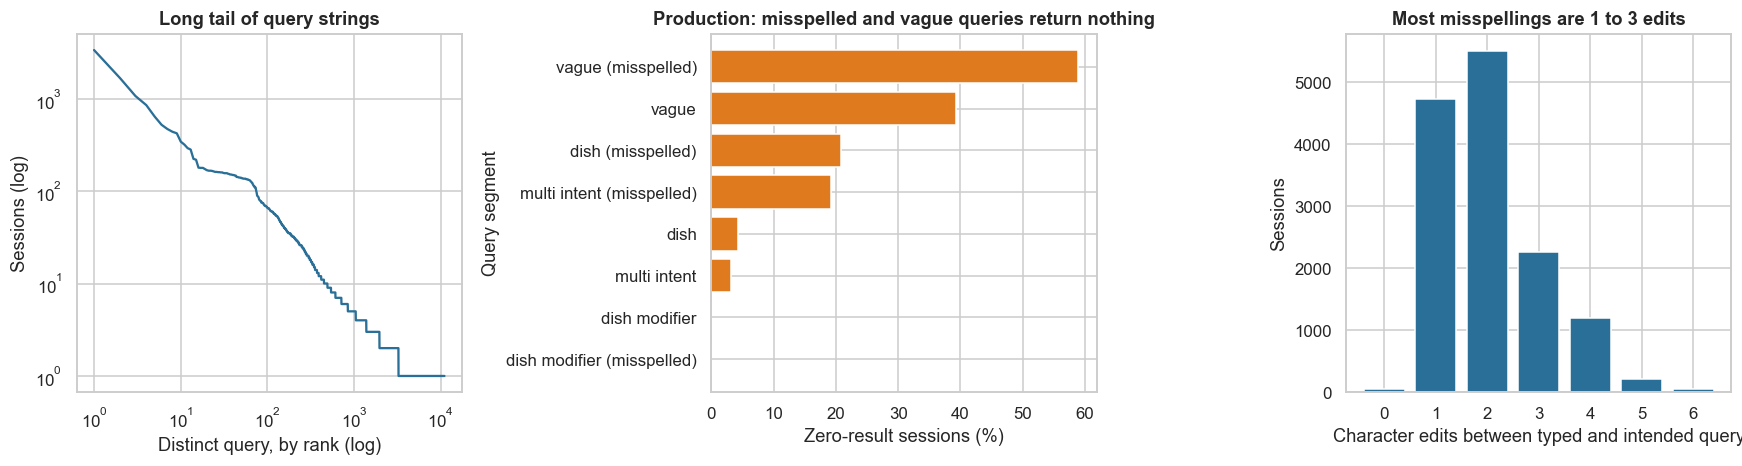

10,981 distinct strings for 47,854 sessions; the 10 most common queries cover 20.4%; zero-result rate in production: clean dish 4.2%, misspelled dish 20.8%, vague 39.3%


In [6]:
s["seg"] = s._type.str.replace("_", " ") + np.where(s._misspelled, " (misspelled)", ""); prod = s[s.served_arm == "production"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
qf = s.q.value_counts().values; axes[0].plot(np.arange(1, len(qf) + 1), qf, color="#2a6f97"); axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("Distinct query, by rank (log)"); axes[0].set_ylabel("Sessions (log)"); axes[0].set_title("Long tail of query strings")
zr = prod.groupby("seg").apply(lambda d: (d.n_results == 0).mean()).sort_values(); axes[1].barh(zr.index, zr.values * 100, color="#e07a1f"); axes[1].set_xlabel("Zero-result sessions (%)"); axes[1].set_ylabel("Query segment"); axes[1].set_title("Production: misspelled and vague queries return nothing")
ed = s[s._misspelled & (s._type != "vague")]._edit_dist.value_counts().sort_index(); axes[2].bar(ed.index.astype(str), ed.values, color="#2a6f97"); axes[2].set_xlabel("Character edits between typed and intended query"); axes[2].set_ylabel("Sessions"); axes[2].set_title("Most misspellings are 1 to 3 edits")
plt.tight_layout(); plt.show()
print(f"{s.q.nunique():,} distinct strings for {len(s):,} sessions; the 10 most common queries cover {qf[:10].sum() / qf.sum():.1%}; zero-result rate in production: clean dish {zr.get('dish', np.nan):.1%}, misspelled dish {zr.get('dish (misspelled)', np.nan):.1%}, vague {zr.get('vague', np.nan):.1%}")

**Takeaway:** query strings have a **long tail** (10,981 strings for 47,854 sessions; the 10 most common cover 20.4%). Production returns nothing for **4.2% of clean dish queries but 20.8% of misspelled dish queries and 39.3% of vague queries**. Most misspellings are 1 to 3 character edits, which is within reach of character-level methods but not of exact matching.

## 7. Statistical Analysis (core section)

### 7.1 Setup: split in time, five retrieval methods, a learned ranker

**Evaluation protocol:** train on **days 0 to 34**, test on **days 53 to 59** (a later week, as Swiggy validates on a week from a much later period). Relevance comes from the hidden graded labels (our stand-in for editorial tags). For every test session we rank the **listings in the customer's area** and score the top 10.

| # | Method | In one line |
|---|---|---|
| 1 | Exact lexical | Word match with idf weights (BM25-like); misspelled words match nothing |
| 2 | **Fuzzy lexical (production-like)** | As 1, with ElasticSearch-style edit-distance tolerance (1 edit for 3 to 5 letters, 2 for 6+) and a popularity tie-break |
| 3 | Character-trigram cosine | TF-IDF over character trigrams of query and menu name; robust to spelling |
| 4 | **Learned query classifier** | Query → dish family: logistic regression on character 2 to 4-grams, trained on **ordered dishes from logs plus a spelling-variation dictionary** (built with only part of the true noise rules and no typing slips) and the menu names; listing score = P(family) + 0.3 P(cluster) |
| 5 | Heuristic blend | Sum of normalised scores of 2, 3 and 4 |
| 6 | **LTR on clicks** | Gradient boosting on 13 features (the four text scores, family and cluster probabilities, rating, distance, prep time, cost, price, popularity, query length), rerank the 40-listing blend pool, label = click on a shown item |
| 7 | LTR, IPW | As 6, with clicks weighted by 1 / examination probability (capped at 5) |
| 8 | LTR, production logs only | As 6, but dropping the 10% trial-arm sessions (selection-bias check) |

No hyper-parameter tuning; all settings are defaults or fixed choices.

#### Code (scoring, stage 1)

In [7]:
TR = s[s.day <= 34].reset_index(drop=True); TE = s[s.day >= 53].reset_index(drop=True)
NN, NF = len(nms), len(fams); nm_fam = nms._family.values; fam_cl = fams.cluster.values; nm_cl = fam_cl[nm_fam]; fam_cat = D["fam_cat"]; nm_cat = fam_cat[nm_fam]
l_name = lst.name_id.values; l_area = lst.area.values; LA = [np.where(l_area == a)[0] for a in range(gen.N_AREA)]; TIE = 0.02 * pd.Series(lst.orders_norm.values).rank(pct=True).values
CLM = np.zeros((NF, 30)); CLM[np.arange(NF), fam_cl] = 1
Lx = gen.Lex(nms.dish_name.tolist()); tri = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), sublinear_tf=True).fit(nms.dish_name); Nv = tri.transform(nms.dish_name)
def text_scores(df):
    uq, qi = np.unique(df.q.values, return_inverse=True)
    return dict(qi=qi, S1=Lx.scores(list(uq), False), S2=Lx.scores(list(uq), True), S3=(tri.transform(uq) @ Nv.T).toarray().astype(np.float32))
t0 = time.time(); XT = text_scores(TE); XR = text_scores(TR)
print(f"train sessions {len(TR):,} (days 0-34) | test sessions {len(TE):,} (days 53-59) | distinct query strings train {len(XR['S1']):,}, test {len(XT['S1']):,} | scored in {time.time() - t0:.0f}s")
print("test sessions by type:", TE._type.value_counts().to_dict(), "| misspelled:", int(TE._misspelled.sum()))

train sessions 27,922 (days 0-34) | test sessions 5,548 (days 53-59) | distinct query strings train 7,533, test 2,220 | scored in 39s
test sessions by type: {'dish': 2872, 'dish_modifier': 1579, 'vague': 660, 'multi_intent': 437} | misspelled: 1739


In [8]:
# Query classifier (method 4): ordered dishes from logs + spelling dictionary + menu names + taxonomy words. Cross-fitted for training sessions (3 folds) so that LTR features are not in-sample.
rng_d = np.random.default_rng(SEED); dic = [(n, f) for n, f in zip(nms.dish_name, nm_fam)]
for f in range(NF): dic += [(gen.misspell(fams.family_name[f], rng_d, rule_n=14, typos=False), f) for _ in range(8)]
for c in range(30): dic += [(gen.CLUSTER_WORDS[c], f) for f in np.where(fam_cl == c)[0]]
dic = pd.DataFrame(dic, columns=["q", "fam"]); ordd = TR[TR.ordered_listing >= 0]; logq = pd.DataFrame({"q": ordd.q.values, "fam": nm_fam[l_name[ordd.ordered_listing.values]], "fold": ordd.session_id.values % 3})
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit(pd.concat([dic.q, logq.q, TR.q]))
def fit_clf(d): return LogisticRegression(C=10, max_iter=100).fit(vec.transform(d.q), d.fam)
def proba(clf, q): u, inv = np.unique(q, return_inverse=True); return clf.predict_proba(vec.transform(u))[inv].astype(np.float32)
t0 = time.time(); P4_tr = np.zeros((len(TR), NF), np.float32); fold = TR.session_id.values % 3
for k in range(3):
    clf_k = fit_clf(pd.concat([dic, logq[logq.fold != k][["q", "fam"]]])); P4_tr[fold == k] = proba(clf_k, TR.q.values[fold == k])
clf = fit_clf(pd.concat([dic, logq[["q", "fam"]]])); P4_te = proba(clf, TE.q.values); PC_tr, PC_te = P4_tr @ CLM, P4_te @ CLM
fam_true = TE._family.values; ok = fam_true >= 0; top1 = P4_te.argmax(1)
acc = pd.DataFrame({"top-1 family accuracy": (top1 == fam_true)[ok], "seg": np.where(TE._misspelled.values[ok], "misspelled", "clean")}).groupby("seg").agg(["mean", "size"])
print(f"order pairs from logs: {len(logq):,} + dictionary/menu/taxonomy pairs: {len(dic):,} | 4 fits in {time.time() - t0:.0f}s")
acc

order pairs from logs: 8,665 + dictionary/menu/taxonomy pairs: 2,280 | 4 fits in 132s


top-1 family accuracy      
                            mean  size
seg                                   
clean                     0.9991  3269
misspelled                0.9555  1619

**Observation:** the query classifier reads the intended dish family correctly for **99.9% of clean** test queries and **95.6% of misspelled** ones (3,269 and 1,619 sessions). It was trained on 8,665 order pairs from the logs plus 2,280 dictionary, menu and taxonomy pairs. The dictionary used a subset of the true spelling rules and no typing slips, so the 95.6% is probably somewhat optimistic compared with a real dictionary.

#### Code (learning to rank, stage 2)

In [9]:
rz = ((lst.rating.values - 4.0) / 0.35); dz = ((lst.dist_km.values - 2.8) / 1.5); pz = lst.orders_norm.values
def feats(sr, l, X, P4, PC, T):
    qi = X["qi"][sr]; nid = l_name[l]
    return pd.DataFrame({"m_exact": X["S1"][qi, nid], "m_fuzzy": X["S2"][qi, nid], "m_trigram": X["S3"][qi, nid], "p_family": P4[sr, nm_fam[nid]], "p_cluster": PC[sr, nm_cl[nid]], "rating": lst.rating.values[l], "dist_km": lst.dist_km.values[l],
                         "prep_min": lst.prep_min.values[l], "cost_for_two": lst.cost_for_two.values[l], "price_inr": lst.price_inr.values[l], "orders_norm": pz[l], "q_tokens": T.n_tok.values[sr], "q_chars": T.q.str.len().values[sr]})
row_of = pd.Series(np.arange(len(TR)), index=TR.session_id.values); itr = imps[imps.session_id.isin(TR.session_id)]; sr_tr = row_of[itr.session_id.values].values
Ftr = feats(sr_tr, itr.listing_id.values, XR, P4_tr, PC_tr, TR); ytr = itr.clicked.values; pos = itr.position.values; arm_tr = TR.served_arm.values[sr_tr]
sub_tr = np.sort(RNG.choice(len(Ftr), 300_000, replace=False)); n_all = len(Ftr); Ftr, ytr, pos, arm_tr = Ftr.iloc[sub_tr], ytr[sub_tr], pos[sub_tr], arm_tr[sub_tr]   # random 300,000 logged impressions (speed)
w_ipw = np.where(ytr == 1, np.minimum(1 / gen.EXAM[pos - 1], 5.0), 1.0); hgb = lambda: HistGradientBoostingClassifier(max_iter=100, random_state=SEED)
t0 = time.time(); L1 = hgb().fit(Ftr, ytr); L2 = hgb().fit(Ftr, ytr, sample_weight=w_ipw); L3 = hgb().fit(Ftr[arm_tr == "production"], ytr[arm_tr == "production"])
print(f"logged training impressions {n_all:,}; random subsample used {len(Ftr):,} (click rate {ytr.mean():.1%}; {int((arm_tr != 'production').sum()):,} from the trial arm) | 3 rankers fitted in {time.time() - t0:.0f}s")
print("features:", ", ".join(Ftr.columns))

logged training impressions 502,151; random subsample used 300,000 (click rate 8.7%; 32,958 from the trial arm) | 3 rankers fitted in 321s
features: m_exact, m_fuzzy, m_trigram, p_family, p_cluster, rating, dist_km, prep_min, cost_for_two, price_inr, orders_norm, q_tokens, q_chars


**Observation:** the ranker was trained on a random 300,000 of 502,151 logged impressions (8.7% clicked; 32,958 of the sample from the n-gram trial arm). Only shown items have labels: items the production system never retrieved, such as those for misspelled queries, appear only through the trial arm. The classifier probabilities in the training features were cross-fitted so the ranker does not see in-sample predictions.

#### Code (rank the test sessions with every method, then score)

In [10]:
SS = {"S1": XT["S1"][XT["qi"]], "S2": XT["S2"][XT["qi"]], "S3": XT["S3"][XT["qi"]]}; SS["S4"] = P4_te[:, nm_fam] + 0.3 * PC_te[:, nm_cl]
SS["BL"] = SS["S3"] + SS["S4"] + 0.5 * SS["S2"] / np.maximum(SS["S2"].max(1, keepdims=True), 1e-9)
def topk(Sn, T, k=10, thr=None):
    out = np.full((len(T), k), -1); ar = T.area.values
    for a in range(gen.N_AREA):
        m = np.where(ar == a)[0]; la = LA[a]; base = Sn[m][:, l_name[la]]; sc = base + TIE[la][None, :]
        if thr is not None: sc = np.where(base > thr, sc, -np.inf)
        idx = np.argpartition(-sc, k, axis=1)[:, :k]; v = np.take_along_axis(sc, idx, 1); o = np.argsort(-v, axis=1, kind="stable"); idx, v = np.take_along_axis(idx, o, 1), np.take_along_axis(v, o, 1)
        lid = la[idx]; lid[~np.isfinite(v)] = -1; out[m] = lid
    return out
TOP = {"1 exact lexical": topk(SS["S1"], TE, thr=0), "2 fuzzy lexical (production-like)": topk(SS["S2"], TE, thr=0), "3 character-trigram cosine": topk(SS["S3"], TE, thr=0.05),
       "4 learned query classifier": topk(SS["S4"], TE), "5 heuristic blend of 2-4": topk(SS["BL"], TE)}
POOL = topk(SS["BL"], TE, k=40); nT = len(TE); srT = np.repeat(np.arange(nT), 40); Fte = feats(srT, POOL.ravel(), XT, P4_te, PC_te, TE)
for name, mdl in (("6 LTR on clicks", L1), ("7 LTR on clicks, IPW", L2), ("8 LTR, production logs only", L3)):
    p = mdl.predict_proba(Fte)[:, 1].reshape(nT, 40); o = np.argsort(-p, axis=1, kind="stable")[:, :10]; TOP[name] = np.take_along_axis(POOL, o, 1)
# ideal ranking per session (area-specific) and metrics
disc = 1 / np.log2(np.arange(2, 12)); intent = TE._intent.values; IG = np.zeros((nT, 10)); ANS = np.zeros(nT, bool)
for a in range(gen.N_AREA):
    m = np.where(TE.area.values == a)[0]; R = -np.sort(-RELM[intent[m]][:, l_name[LA[a]]], axis=1)[:, :10]; IG[m] = np.cumsum((2.0 ** R - 1) * disc, 1); ANS[m] = R[:, 0] == 3
catT = np.where(TE._family.values >= 0, fam_cat[np.maximum(TE._family.values, 0)], TE._cluster.values // 5)
ATT = lambda rel, l: 1 / (1 + np.exp(-(gen.A_REL[rel] + 0.55 * rz[l] + (-0.25) * dz[l] + 0.20 * pz[l])))
def evaluate(top):
    valid = top >= 0; lid = np.maximum(top, 0); rel = np.where(valid, RELM[intent[:, None], l_name[lid]], 0); G = np.cumsum((2.0 ** rel - 1) * valid * disc, 1)
    nd = {k: np.where(IG[:, k - 1] > 0, G[:, k - 1] / np.maximum(IG[:, k - 1], 1e-9), 0) for k in (1, 3, 5, 10)}
    first = np.where((rel == 3).any(1), (rel == 3).argmax(1) + 1, 0); rr = np.where(first > 0, 1 / np.maximum(first, 1), 0.0)
    catshare = np.where(valid, nm_cat[l_name[lid]] == catT[:, None], False).sum(1) / np.maximum(valid.sum(1), 1)
    pclick = np.where(valid, gen.EXAM[:10][None, :] * ATT(rel, lid), 0.0); succ = 1 - np.prod(1 - pclick, 1)
    return dict(ndcg1=nd[1], ndcg3=nd[3], ndcg5=nd[5], ndcg=nd[10], rr=rr, p1=(rel[:, 0] == 3).astype(float), zero=(~valid[:, 0]).astype(float), catshare=catshare, succ=succ, rel=rel)
MET = {k: evaluate(v) for k, v in TOP.items()}; names_m = list(MET)
def boot_ci(x, B=500):
    idx = RNG.integers(0, len(x), (B, len(x))); b = x[idx].mean(1); return np.percentile(b, 2.5), np.percentile(b, 97.5)
rows = []
for k in names_m:
    m = MET[k]; lo, hi = boot_ci(m["ndcg"]); rows.append((k, m["ndcg"].mean(), lo, hi, m["ndcg1"].mean(), m["ndcg3"].mean(), m["rr"][ANS].mean(), m["p1"][ANS].mean(), m["zero"].mean(), m["succ"].mean()))
res = pd.DataFrame(rows, columns=["method", "NDCG@10", "CI low", "CI high", "NDCG@1", "NDCG@3", "MRR@10 (answerable)", "P@1 (answerable)", "zero-result rate", "twin P(click)"]).set_index("method")
print(f"test sessions {nT:,}; answerable (an exact-dish listing exists in the area): {ANS.mean():.1%}; LTR pool of 40 contains an exact-dish listing for {np.mean([(RELM[intent[i]][l_name[POOL[i]]] == 3).any() for i in np.where(ANS)[0]]):.1%} of answerable sessions")
res.round(4)

test sessions 5,548; answerable (an exact-dish listing exists in the area): 81.5%; LTR pool of 40 contains an exact-dish listing for 95.0% of answerable sessions


,NDCG@10,CI low,CI high,NDCG@1,NDCG@3,MRR@10 (answerable),P@1 (answerable),zero-result rate,twin P(click)
method,,,,,,,,,
1 exact lexical,0.6730,0.6616,0.6843,0.6745,0.6726,0.7217,0.7169,0.2022,0.5428
2 fuzzy lexical (production-like),0.7763,0.7662,0.7862,0.7821,0.7803,0.8402,0.8381,0.1081,0.6224
3 character-trigram cosine,0.8131,0.8038,0.8227,0.8175,0.8163,0.8763,0.8713,0.0094,0.6482
4 learned query classifier,0.8783,0.8716,0.8844,0.8666,0.8679,0.7877,0.7605,0.0000,0.7010
5 heuristic blend of 2-4,0.8934,0.8863,0.9014,0.8983,0.8973,0.9170,0.9160,0.0000,0.6913
6 LTR on clicks,0.9004,0.8940,0.9070,0.9139,0.9109,0.9195,0.9023,0.0000,0.7909
"7 LTR on clicks, IPW",0.8961,0.8894,0.9026,0.9101,0.9041,0.9046,0.8799,0.0000,0.8117
"8 LTR, production logs only",0.8958,0.8895,0.9030,0.9033,0.9004,0.9042,0.8782,0.0000,0.7887


**(c)/(f) Observation:** **(c)** NDCG@10 rises from **0.673 (exact)** to **0.776 (fuzzy, production-like)**, **0.813 (trigram)**, **0.878 (classifier)**, **0.893 (blend)** and **0.900 (LTR on clicks)**; IPW 0.896, production-logs-only 0.896. Zero-result rates: 20.2% exact, 10.8% fuzzy, 0.9% trigram, 0% for the rest. The classifier has a lower MRR@10 (0.788) and P@1 (0.761) than fuzzy matching (0.840 and 0.838) because it knows the family but not the modifier ("chicken biryani"), so it can put a plain biryani first. The blend and LTR have MRR 0.917 and 0.920. **(f)** NDCG@1, @3 and @10 order the methods the same way, but the exact-dish metrics (MRR, P@1) rank the classifier below fuzzy matching: pick the metric that matches the product question.

### 7.2 Is the winner really better? Paired tests on the same sessions

**(a) Why?** Every method is scored on the **same test sessions**, so the tests are paired: a **Wilcoxon signed-rank** test and a **paired bootstrap** CI (1,000 resamples) on the NDCG@10 difference, with **Holm** across the seven comparisons and **Cohen's d_z** as the effect size. We compare the best method with each of the others. NDCG per session is bounded and has many ties and zeros, so the rank test and the bootstrap are safer than a paired t-test.

#### Code

In [11]:
best = res["NDCG@10"].idxmax(); rows = []
for k in names_m:
    if k == best: continue
    d = MET[best]["ndcg"] - MET[k]["ndcg"]; bs = np.array([d[RNG.integers(0, len(d), len(d))].mean() for _ in range(1000)])
    try: pw = stats.wilcoxon(d).pvalue
    except ValueError: pw = 1.0
    rows.append((k, d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), d.mean() / d.std(ddof=1), pw, int((d > 1e-9).sum()), int((d < -1e-9).sum())))
pt = pd.DataFrame(rows, columns=[f"vs {best}", "ΔNDCG@10 (best − other)", "CI low", "CI high", "Cohen d_z", "Wilcoxon p", "sessions best wins", "sessions other wins"]).set_index(f"vs {best}"); pt["p_holm"] = multipletests(pt["Wilcoxon p"], method="holm")[1]
print(f"Best method on NDCG@10: {best}"); pt.round(4)

Best method on NDCG@10: 6 LTR on clicks


,ΔNDCG@10 (best − other),CI low,CI high,Cohen d_z,Wilcoxon p,sessions best wins,sessions other wins,p_holm
vs 6 LTR on clicks,,,,,,,,
1 exact lexical,0.2275,0.2158,0.2387,0.5502,0.0000,1682,787,0.0000
2 fuzzy lexical (production-like),0.1242,0.1160,0.1327,0.3697,0.0000,1118,908,0.0000
3 character-trigram cosine,0.0874,0.0798,0.0950,0.2945,0.0000,978,993,0.0000
4 learned query classifier,0.0221,0.0160,0.0286,0.0999,0.0000,942,623,0.0000
5 heuristic blend of 2-4,0.0070,0.0029,0.0112,0.0444,0.0000,362,1057,0.0000
"7 LTR on clicks, IPW",0.0043,0.0028,0.0060,0.0718,0.0000,799,612,0.0000
"8 LTR, production logs only",0.0046,0.0031,0.0061,0.0769,0.0000,809,548,0.0000


**(c)/(f) Observation:** **(c)** The LTR on clicks beats every other method on the same sessions: **+0.124 over production-like** (CI 0.116 to 0.133), +0.087 over trigram, +0.022 over the classifier, **+0.007 over the blend** (CI 0.003 to 0.011), +0.004 over IPW and +0.005 over production-logs-only (all Holm p < 1e-4). The effect sizes (d_z) are 0.37 against production but only 0.04 to 0.08 against the three close methods. **(f)** With 5,548 sessions even tiny gaps are significant, so judge by size: the ranker's advantage over the blend and over its own variants is real but small.

#### Chart: NDCG at several cut-offs and the zero-result rate

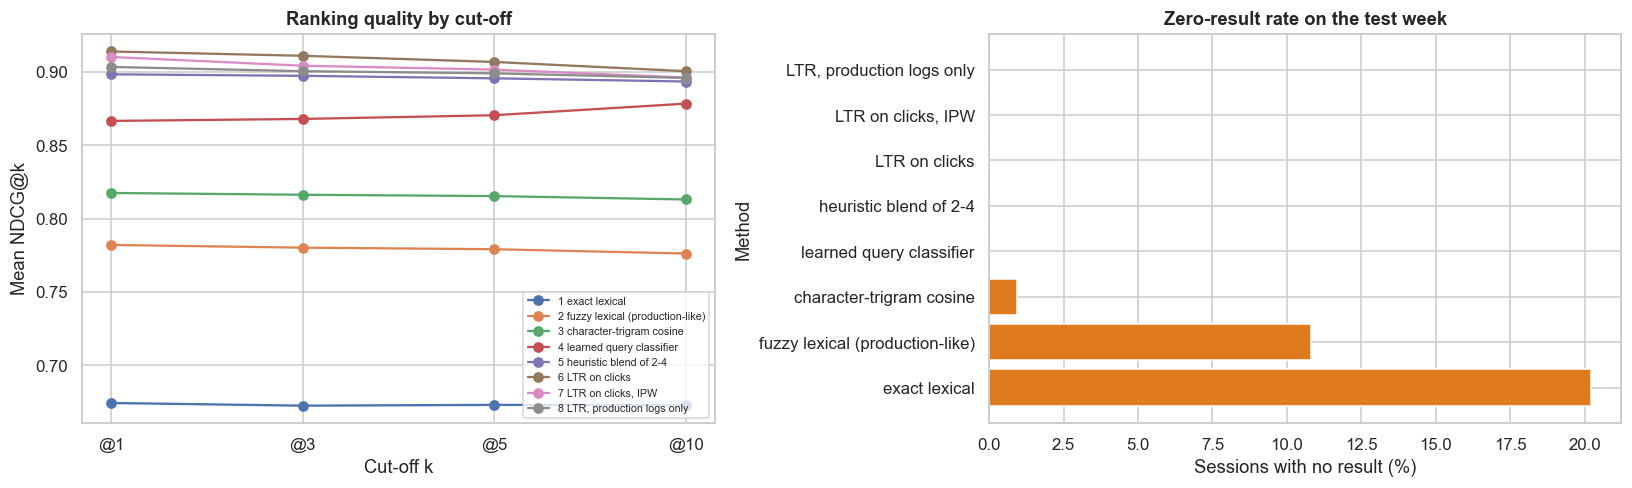

{'1 exact lexical': np.float64(0.674), '2 fuzzy lexical (production-like)': np.float64(0.782), '3 character-trigram cosine': np.float64(0.817), '4 learned query classifier': np.float64(0.867), '5 heuristic blend of 2-4': np.float64(0.898), '6 LTR on clicks': np.float64(0.914), '7 LTR on clicks, IPW': np.float64(0.91), '8 LTR, production logs only': np.float64(0.903)}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6)); ks = [1, 3, 5, 10]
for k in names_m: axes[0].plot([f"@{x}" for x in ks], [MET[k][{1: "ndcg1", 3: "ndcg3", 5: "ndcg5", 10: "ndcg"}[x]].mean() for x in ks], marker="o", label=k)
axes[0].set_xlabel("Cut-off k"); axes[0].set_ylabel("Mean NDCG@k"); axes[0].set_title("Ranking quality by cut-off"); axes[0].legend(fontsize=7, loc="lower right")
zz = res["zero-result rate"].sort_values(ascending=False); axes[1].barh([x.split(" ", 1)[1][:34] for x in zz.index], zz.values * 100, color="#e07a1f"); axes[1].set_xlabel("Sessions with no result (%)"); axes[1].set_ylabel("Method"); axes[1].set_title("Zero-result rate on the test week")
plt.tight_layout(); plt.show()
print({k: round(MET[k]["ndcg1"].mean(), 3) for k in names_m})

**Takeaway:** NDCG climbs steeply with better methods at every cut-off, and NDCG@1 is highest for the LTR (0.914) and lowest for exact matching (0.675). The right-hand panel shows the cost of word matching: production-like returns nothing for **10.8%** of searches, exact matching for **20.2%**; the learned methods return something for every session. Getting the first result right (NDCG@1) matters most for search, and that is where LTR (0.914) beats the blend (0.898) and the classifier (0.867).

### 7.3 Misspellings: who benefits? (difference-in-differences and the edit-distance trend)

**(a) Why?** The Swiggy posts report the largest gains on the **misspelled set (V2)**. We split plain-dish-like sessions (dish, dish + modifier, multi-intent) into **clean** and **misspelled**, compare each method, and test the **interaction**: is the gain of the best character-level method over fuzzy word match bigger for misspelled queries? Difference-in-differences with a bootstrap CI over sessions; plus NDCG by **number of character edits** (0, 1, 2, 3+) and a Spearman trend test for the fuzzy baseline.

#### Code

Spearman(edits, NDCG@10) among misspelled sessions: fuzzy lexical -0.30 (p = 9.1e-36); learned classifier -0.03 (p = 0.2) | misspelled share of dish-like test sessions: 33.1%


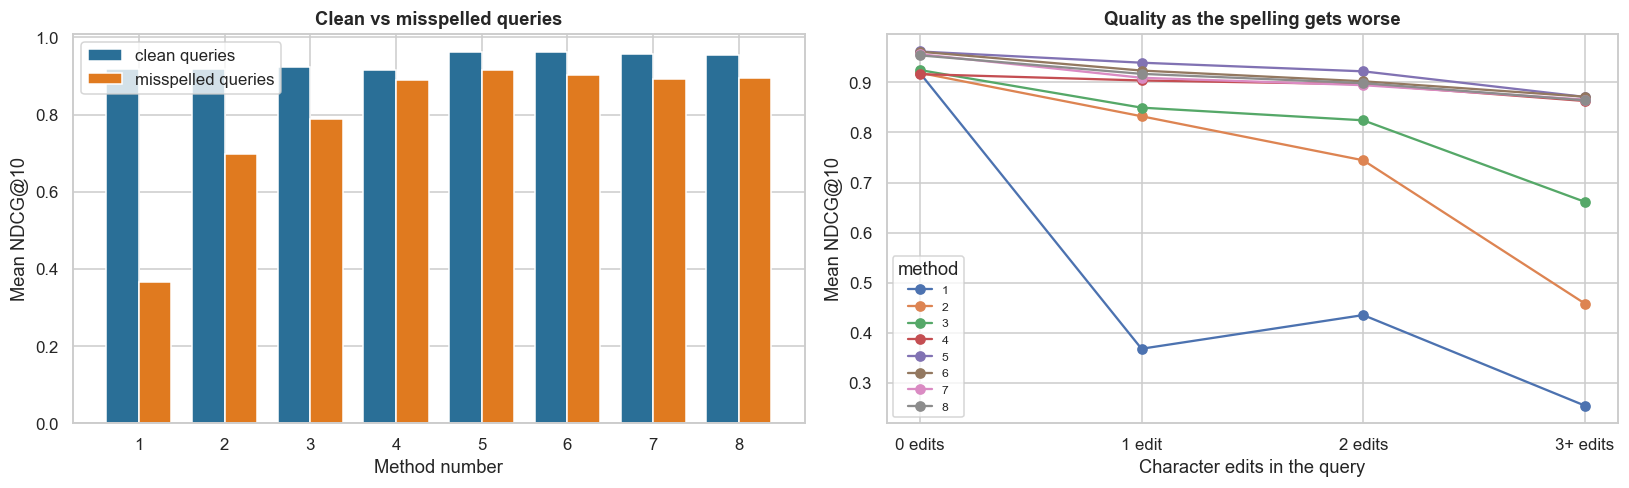

,clean,misspelled,gap (clean − misspelled)
1 exact lexical,0.9189,0.3658,0.5531
2 fuzzy lexical (production-like),0.9189,0.6976,0.2213
3 character-trigram cosine,0.9242,0.7896,0.1346
4 learned query classifier,0.9160,0.8901,0.0259
5 heuristic blend of 2-4,0.9613,0.9143,0.0471
6 LTR on clicks,0.9610,0.9013,0.0597
"7 LTR on clicks, IPW",0.9559,0.8920,0.0639
"8 LTR, production logs only",0.9538,0.8953,0.0586


,gain on clean,gain on misspelled,diff-in-diff,CI low,CI high,Mann-Whitney p
method − fuzzy lexical,,,,,,
1 exact lexical,-0.0000,-0.3318,-0.3318,-0.3528,-0.3101,0.0000
3 character-trigram cosine,0.0053,0.0919,0.0867,0.0676,0.1035,0.0000
4 learned query classifier,-0.0029,0.1925,0.1954,0.1680,0.2216,0.0000
6 LTR on clicks,0.0420,0.2037,0.1616,0.1415,0.1846,0.0000


,exact lexical,fuzzy lexical (production-li,character-trigram cosine,learned query classifier,heuristic blend of 2-4,LTR on clicks,"LTR on clicks, IPW","LTR, production logs only"
0 edits,0.9190,0.9190,0.9240,0.9160,0.9610,0.9610,0.9560,0.9540
1 edit,0.3680,0.8320,0.8490,0.9040,0.9390,0.9230,0.9090,0.9170
2 edits,0.4360,0.7440,0.8240,0.8960,0.9220,0.9020,0.8940,0.8980
3+ edits,0.2550,0.4580,0.6610,0.8630,0.8710,0.8710,0.8650,0.8640


In [13]:
dishlike = (TE._type.values != "vague"); mis = TE._misspelled.values; edv = TE._edit_dist.values; fz = "2 fuzzy lexical (production-like)"
cm = pd.DataFrame({k: {"clean": MET[k]["ndcg"][dishlike & ~mis].mean(), "misspelled": MET[k]["ndcg"][dishlike & mis].mean(), "gap (clean − misspelled)": MET[k]["ndcg"][dishlike & ~mis].mean() - MET[k]["ndcg"][dishlike & mis].mean()} for k in names_m}).T
alt = [k for k in names_m if k != fz][:3] + ["6 LTR on clicks"]; did = []
for k in alt:
    d = MET[k]["ndcg"] - MET[fz]["ndcg"]; a, b = d[dishlike & mis], d[dishlike & ~mis]; bs = [RNG.choice(a, len(a)).mean() - RNG.choice(b, len(b)).mean() for _ in range(1000)]
    did.append((k, b.mean(), a.mean(), a.mean() - b.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), stats.mannwhitneyu(a, b).pvalue))
did = pd.DataFrame(did, columns=["method − fuzzy lexical", "gain on clean", "gain on misspelled", "diff-in-diff", "CI low", "CI high", "Mann-Whitney p"]).set_index("method − fuzzy lexical")
eb = np.minimum(edv, 3); ed_tab = pd.DataFrame({k.split(" ", 1)[1][:28]: [MET[k]["ndcg"][dishlike & (eb == e)].mean() for e in range(4)] for k in names_m}, index=["0 edits", "1 edit", "2 edits", "3+ edits"])
rho, prho = stats.spearmanr(edv[dishlike & mis], MET[fz]["ndcg"][dishlike & mis]); rho4, prho4 = stats.spearmanr(edv[dishlike & mis], MET["4 learned query classifier"]["ndcg"][dishlike & mis])
print(f"Spearman(edits, NDCG@10) among misspelled sessions: fuzzy lexical {rho:+.2f} (p = {prho:.2g}); learned classifier {rho4:+.2f} (p = {prho4:.2g}) | misspelled share of dish-like test sessions: {mis[dishlike].mean():.1%}")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6)); xx = np.arange(len(names_m)); w = 0.38
axes[0].bar(xx - w / 2, cm["clean"], w, label="clean queries", color="#2a6f97"); axes[0].bar(xx + w / 2, cm["misspelled"], w, label="misspelled queries", color="#e07a1f"); axes[0].set_xticks(xx); axes[0].set_xticklabels([x.split(" ")[0] for x in names_m]); axes[0].set_xlabel("Method number"); axes[0].set_ylabel("Mean NDCG@10"); axes[0].set_title("Clean vs misspelled queries"); axes[0].legend()
for k in names_m: axes[1].plot(ed_tab.index, ed_tab[k.split(" ", 1)[1][:28]], marker="o", label=k.split(" ")[0])
axes[1].set_xlabel("Character edits in the query"); axes[1].set_ylabel("Mean NDCG@10"); axes[1].set_title("Quality as the spelling gets worse"); axes[1].legend(title="method", fontsize=8)
plt.tight_layout(); plt.show()
display(cm.round(4)); display(did.round(4)); ed_tab.round(3)

**Takeaway:** **misspelled queries:** NDCG@10 for fuzzy matching drops from **0.919 clean to 0.698 misspelled** (gap 0.221), exact matching from 0.919 to 0.366, trigram from 0.924 to 0.790, the classifier from 0.916 to **0.890** (gap 0.026), the blend from 0.961 to 0.914. The difference-in-differences against fuzzy matching is **+0.087 for trigram** (CI 0.068 to 0.104), **+0.195 for the classifier** (CI 0.168 to 0.222) and +0.162 for the ranker (CI 0.142 to 0.185); gains on clean queries are about zero for the text methods (the ranker gains +0.042 from business features). Fuzzy NDCG falls with edits (Spearman -0.30, p < 1e-30; 1 edit 0.832, 2 edits 0.744, 3+ edits 0.458); the classifier shows no trend (-0.03, p = 0.2; 3+ edits 0.863). H2 is rejected: the gain is concentrated in misspelled queries.

### 7.4 Query types and availability: where does each method struggle?

**(a) Why?** Averages hide segments. We report NDCG@10 by **query type**, test the **heterogeneity** for the best method (Kruskal–Wallis across types), and look at **unavailable dishes** (no exact-dish listing in the customer's area): there the right answer is a close alternative, and we also report the share of the top 10 that sits in the **intended category** (the Swiggy check for queries that used to return nothing).

#### Code

In [14]:
typ = TE._type.values; seg_tab = pd.DataFrame({k.split(" ", 1)[1][:28]: {t: MET[k]["ndcg"][typ == t].mean() for t in ("dish", "dish_modifier", "multi_intent", "vague")} for k in names_m}).T
kw = stats.kruskal(*[MET[best]["ndcg"][typ == t] for t in ("dish", "dish_modifier", "multi_intent", "vague")])
unav = (~ANS) & (typ != "vague"); av = ANS & (typ != "vague"); zr_old = MET[fz]["zero"] == 1
rows = []
for k in names_m:
    m = MET[k]; rows.append((k, m["ndcg"][av].mean(), m["ndcg"][unav].mean(), m["catshare"][unav].mean(), m["catshare"][zr_old & dishlike].mean() if (zr_old & dishlike).any() else np.nan, m["ndcg"][zr_old & dishlike].mean() if (zr_old & dishlike).any() else np.nan))
av_tab = pd.DataFrame(rows, columns=["method", "NDCG@10: dish available", f"NDCG@10: dish unavailable (n = {int(unav.sum())})", "top-10 in intended category (unavailable)", f"top-10 in intended category (production zero-result, n = {int((zr_old & dishlike).sum())})", "NDCG@10 (production zero-result)"]).set_index("method")
print(f"Kruskal-Wallis across query types for {best}: H = {kw.statistic:.1f}, p = {kw.pvalue:.2g} | share of dish-like test sessions with no exact dish in the area: {unav.sum() / dishlike.sum():.1%}")
display(seg_tab.round(3)); av_tab.round(3)

Kruskal-Wallis across query types for 6 LTR on clicks: H = 1274.4, p = 5.3e-276 | share of dish-like test sessions with no exact dish in the area: 21.0%


,dish,dish_modifier,multi_intent,vague
exact lexical,0.7300,0.7390,0.7590,0.2080
fuzzy lexical (production-li,0.8600,0.8160,0.8590,0.2620
character-trigram cosine,0.8980,0.8410,0.8980,0.3200
learned query classifier,0.9910,0.7340,0.9850,0.6630
heuristic blend of 2-4,0.9560,0.9260,0.9490,0.5060
LTR on clicks,0.9680,0.8840,0.9680,0.5980
"LTR on clicks, IPW",0.9750,0.8520,0.9710,0.6100
"LTR, production logs only",0.9600,0.8780,0.9680,0.6100


,NDCG@10: dish available,NDCG@10: dish unavailable (n = 1026),top-10 in intended category (unavailable),"top-10 in intended category (production zero-result, n = 313)",NDCG@10 (production zero-result)
method,,,,,
1 exact lexical,0.8090,0.4610,0.5540,0.0000,0.0000
2 fuzzy lexical (production-like),0.9360,0.5050,0.5900,0.0000,0.0000
3 character-trigram cosine,0.9680,0.5480,0.6650,0.5420,0.4340
4 learned query classifier,0.8890,0.9750,0.9840,0.9650,0.9500
5 heuristic blend of 2-4,0.9910,0.7740,0.8260,0.8850,0.8260
6 LTR on clicks,0.9630,0.8600,0.8830,0.9220,0.9010
"7 LTR on clicks, IPW",0.9520,0.8690,0.8860,0.9190,0.9000
"8 LTR, production logs only",0.9540,0.8630,0.8840,0.9290,0.9080


**Observation:** NDCG@10 differs strongly by query type (Kruskal-Wallis H = 1,274 for the ranker). Plain dish queries score 0.968 for the ranker, dish + modifier 0.884, multi-intent 0.968 and **vague 0.598**; fuzzy matching gets 0.860, 0.816, 0.859 and 0.262. The classifier is best on plain and multi-intent queries (0.991, 0.985) but weak on modifiers (0.734). **When the dish is unavailable (1,026 sessions)** fuzzy matching gets 0.505, trigram 0.548, the ranker 0.860 and the classifier **0.975**, with 98.4% of its top 10 in the intended category. For the 313 sessions where production returned nothing, the classifier reaches NDCG 0.950 and 96.5% in-category, the ranker 0.901 and 92.2%, trigram only 0.434 and 54.2%. The blend does best when the dish exists (0.991) and the classifier when it does not, which is why the combined methods are strong.

### 7.5 Embeddings: do character trigrams cluster dish families? (Davies-Bouldin and out-of-vocabulary)

**(a) Why?** Swiggy checks that embeddings group dishes by family (Davies-Bouldin index, lower is better) and notes that word-level embeddings could not embed about 32% of dishes. We take **10 head families × 150 test queries** (clean and misspelled) and embed them two ways: (i) **word-level** TF-IDF over the menu vocabulary (unseen words are dropped, so a fully misspelled query becomes a zero vector), (ii) **character-trigram** TF-IDF; both reduced to 64 dimensions by SVD fitted on menu names only. We report the Davies-Bouldin index of each, the **out-of-vocabulary rate** of word-level matching, and a 2-D picture.

#### Code

Davies-Bouldin (lower = tighter family clusters): word-level 0.89 | character-trigram 0.36 | share of sampled queries with no known word: all 22.0%, misspelled 66.7%, clean 0.0% | all dish-like test queries with no known word: 12.5%


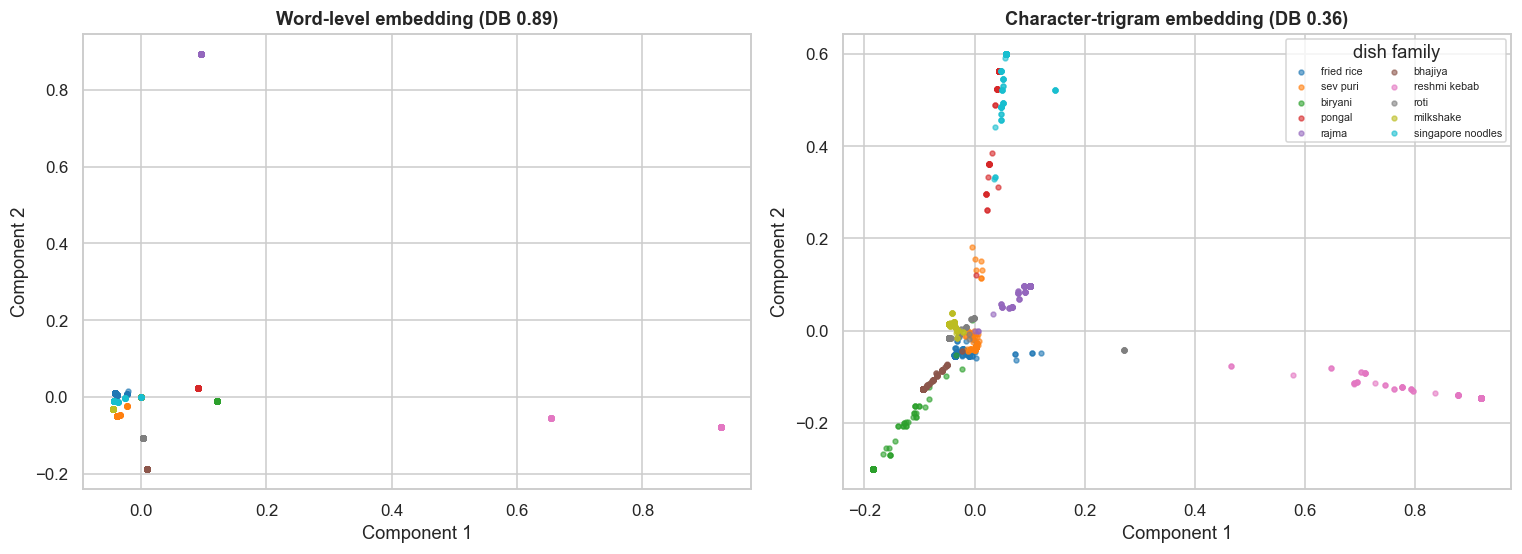

In [15]:
head = np.argsort(-fams._demand_weight.values)[:10]; sel = []
for f in head:
    idx = np.where((TE._family.values == f) & (TE._type.values == "dish"))[0]; sel.append(RNG.choice(idx, 150, replace=len(idx) < 150))
sel = np.concatenate(sel); qs = TE.q.values[sel]; labs = TE._family.values[sel]; names_txt = nms.dish_name.tolist()
wv = TfidfVectorizer(analyzer="word", sublinear_tf=True).fit(names_txt); tv = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 3), sublinear_tf=True).fit(names_txt)
sw = TruncatedSVD(64, random_state=SEED).fit(wv.transform(names_txt)); st = TruncatedSVD(64, random_state=SEED).fit(tv.transform(names_txt))
Ew, Et = sw.transform(wv.transform(qs)), st.transform(tv.transform(qs)); oov = np.asarray(wv.transform(qs).sum(1)).ravel() == 0
dbw, dbt = davies_bouldin_score(Ew, labs), davies_bouldin_score(Et, labs)
mis_q = TE._misspelled.values[sel]; tokv = set(wv.vocabulary_); oov_rate_all = np.mean([not any(t in tokv for t in q.split()) for q in TE.q.values[dishlike]])
print(f"Davies-Bouldin (lower = tighter family clusters): word-level {dbw:.2f} | character-trigram {dbt:.2f} | share of sampled queries with no known word: all {oov.mean():.1%}, misspelled {oov[mis_q].mean():.1%}, clean {oov[~mis_q].mean():.1%} | all dish-like test queries with no known word: {oov_rate_all:.1%}")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2)); pal = sns.color_palette("tab10", 10)
for ax, E, ttl in ((axes[0], Ew, "Word-level embedding"), (axes[1], Et, "Character-trigram embedding")):
    Z = TruncatedSVD(2, random_state=SEED).fit_transform(E + RNG.normal(0, 1e-6, E.shape))
    for j, f in enumerate(head): ax.scatter(Z[labs == f, 0], Z[labs == f, 1], s=10, color=pal[j], alpha=0.6, label=fams.family_name[f] if ax is axes[1] else None)
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2"); ax.set_title(ttl + f" (DB {dbw if ax is axes[0] else dbt:.2f})")
axes[1].legend(fontsize=7, ncol=2, title="dish family"); plt.tight_layout(); plt.show()

**Takeaway:** character trigrams cluster dish families much better than words: **Davies-Bouldin 0.36 vs 0.89** (lower is better), the same direction as Swiggy's use of the index. Word-level embeddings cannot embed **66.7% of the sampled misspelled queries** (22.0% of the sample overall; 12.5% of all dish-like test queries have no known word, and no clean query has none), so those fall on a single point. The right-hand panel shows tighter, better separated groups than the left.

### 7.6 Clicks as labels: position bias, replay metrics and offline vs online agreement

**(a) Why?** Click logs are the cheap labels, but (i) users **examine top positions more**, (ii) clicks only exist for what the **old system showed**, and (iii) clicks miss relevant items nobody saw. We (1) look at the click rate **by position for exact-dish listings** (a flat curve would mean no bias), fitted with a logistic regression of click on log-position and relevance; (2) measure **label noise**: the share of clicks on exact-dish listings and the share of exact-dish listings that were shown but not clicked; (3) compare three ways of ranking the methods: **editorial NDCG@10** (hidden truth), **click replay** (does the item the customer actually ordered appear in the method's top 10? only for test sessions with an order), and the **online twin** (expected probability of at least one click); each pair tested with Spearman (H5).

#### Code

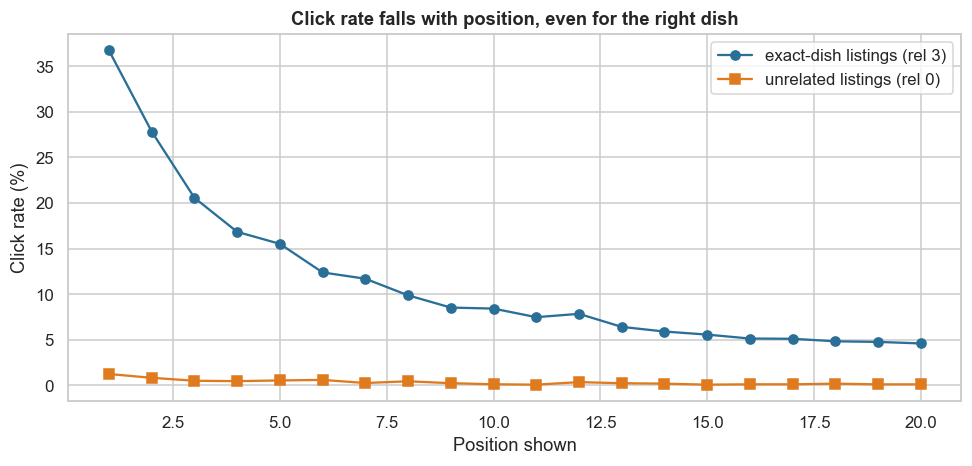

Logistic fit: coefficient on log(position) = -0.85 (95% CI -0.86 to -0.84); odds of a click at position 10 vs 1 for the same relevance: 0.14
Click-label noise: 91.5% of clicks are on exact-dish listings, 0.4% on unrelated ones | 88.2% of exact-dish listings that were shown were not clicked | exact-dish share of the top-20 shown: 68.9%


Spearman of method ranks: editorial vs replay -0.31 (p = 0.46) | editorial vs twin +0.95 (p = 0.00026) | replay vs twin -0.52 (p = 0.18) | test sessions with an order: 1,706


,editorial NDCG@10,click replay: ordered dish in top 10,online twin P(click),rank editorial,rank replay,rank twin
1 exact lexical,0.6730,0.7737,0.5428,8.0000,5.0000,8.0000
2 fuzzy lexical (production-like),0.7763,0.8834,0.6224,7.0000,1.0000,7.0000
3 character-trigram cosine,0.8131,0.8271,0.6482,6.0000,3.0000,6.0000
4 learned query classifier,0.8783,0.4197,0.7010,5.0000,8.0000,4.0000
5 heuristic blend of 2-4,0.8934,0.8359,0.6913,4.0000,2.0000,5.0000
6 LTR on clicks,0.9004,0.7773,0.7909,1.0000,4.0000,2.0000
"7 LTR on clicks, IPW",0.8961,0.5920,0.8117,2.0000,7.0000,1.0000
"8 LTR, production logs only",0.8958,0.7696,0.7887,3.0000,6.0000,3.0000


In [16]:
iv = itr.merge(TR[["session_id", "_intent", "served_arm"]], on="session_id"); iv["rel"] = RELM[iv._intent.values, l_name[iv.listing_id.values]]; pv = iv[iv.served_arm == "production"].copy()
ctr_pos = pv[pv.rel == 3].groupby("position").clicked.mean(); ctr_pos_hi = pv[pv.rel == 0].groupby("position").clicked.mean()
lg = smf.logit("clicked ~ np.log(position) + C(rel)", data=pv).fit(disp=0)
fig, ax = plt.subplots(figsize=(9, 4.4)); ax.plot(ctr_pos.index, ctr_pos.values * 100, marker="o", color="#2a6f97", label="exact-dish listings (rel 3)"); ax.plot(ctr_pos_hi.index, ctr_pos_hi.values * 100, marker="s", color="#e07a1f", label="unrelated listings (rel 0)")
ax.set_xlabel("Position shown"); ax.set_ylabel("Click rate (%)"); ax.set_title("Click rate falls with position, even for the right dish"); ax.legend(); plt.tight_layout(); plt.show()
shown3 = pv[pv.rel == 3]; clicks = pv[pv.clicked == 1]
print(f"Logistic fit: coefficient on log(position) = {lg.params['np.log(position)']:+.2f} (95% CI {lg.conf_int().loc['np.log(position)', 0]:+.2f} to {lg.conf_int().loc['np.log(position)', 1]:+.2f}); odds of a click at position 10 vs 1 for the same relevance: {np.exp(lg.params['np.log(position)'] * np.log(10)):.2f}")
print(f"Click-label noise: {(clicks.rel == 3).mean():.1%} of clicks are on exact-dish listings, {(clicks.rel == 0).mean():.1%} on unrelated ones | {1 - shown3.clicked.mean():.1%} of exact-dish listings that were shown were not clicked | exact-dish share of the top-20 shown: {(pv.rel == 3).mean():.1%}")
orde = np.where(TE.ordered_listing.values >= 0)[0]; replay = {k: np.mean([(TOP[k][i] == TE.ordered_listing.values[i]).any() for i in orde]) for k in names_m}
cmp_ = pd.DataFrame({"editorial NDCG@10": res["NDCG@10"], "click replay: ordered dish in top 10": pd.Series(replay), "online twin P(click)": res["twin P(click)"]})
cmp_["rank editorial"] = cmp_.iloc[:, 0].rank(ascending=False); cmp_["rank replay"] = cmp_.iloc[:, 1].rank(ascending=False); cmp_["rank twin"] = cmp_.iloc[:, 2].rank(ascending=False)
r_er, p_er = stats.spearmanr(cmp_["rank editorial"], cmp_["rank replay"]); r_et, p_et = stats.spearmanr(cmp_["rank editorial"], cmp_["rank twin"]); r_rt, p_rt = stats.spearmanr(cmp_["rank replay"], cmp_["rank twin"])
print(f"Spearman of method ranks: editorial vs replay {r_er:+.2f} (p = {p_er:.2g}) | editorial vs twin {r_et:+.2f} (p = {p_et:.2g}) | replay vs twin {r_rt:+.2f} (p = {p_rt:.2g}) | test sessions with an order: {len(orde):,}")
cmp_.round(4)

**Takeaway:** **position bias:** for the same relevance, the odds of a click at position 10 are **0.14** of those at position 1 (log-position coefficient -0.85, CI -0.86 to -0.84); the curve falls steadily even for exact-dish listings. **Label noise:** 91.5% of clicks are on exact-dish listings (0.4% on unrelated), but **88.2% of exact-dish listings that were shown were not clicked**, so clicks undercount relevance. **Replay metric:** ranking the methods by whether the ordered dish is in the top 10 puts fuzzy lexical first (0.883) and the classifier last (0.420); its Spearman with editorial NDCG is **-0.31** (p = 0.46) and with the online twin **-0.52** (p = 0.18), neither significant with 8 methods but pointing the wrong way. Editorial NDCG and the twin agree (**+0.95**, p = 0.0003). H5 is rejected for replay as a decision metric: it rewards agreement with the logging system. The twin's click model includes rating and distance, so it rates the IPW ranker (0.812) above the LTR (0.791) while editorial NDCG does not.

### 7.7 How many judged queries and how big an A/B test? Sample-size and power

**(a) Why?** Swiggy's 2024 test set had 5,000+ labelled samples. How many do we need? With a paired design the required number of **sessions** for a mean NDCG difference Δ is n = ((z₍α/2₎ + z₍β₎) · SD(d) / Δ)², using the observed SD of the per-session difference between the best method and the production-like baseline (80% power, two-sided α = 0.05). The **minimum detectable difference** on our test set follows from the same formula. For the live test, the outcome is the share of search sessions with at least one click, and the sample size per arm for a **relative** lift is the usual two-proportion formula.

#### Code

In [17]:
d = MET[best]["ndcg"] - MET[fz]["ndcg"]; sd = d.std(ddof=1); zz = 1.96 + 0.84
rows = [(f"ΔNDCG@10 = {D_:.3f}", int(np.ceil((zz * sd / D_) ** 2))) for D_ in (0.005, 0.01, 0.02, 0.05)]
print(f"Observed paired SD of the NDCG@10 difference (best − production-like): {sd:.3f}; mean difference {d.mean():.3f}; minimum detectable difference with our {nT:,} test sessions: {zz * sd / np.sqrt(nT):.4f}")
p0 = MET[fz]["succ"].mean(); base_click = (TE[TE.served_arm == "production"].n_clicks > 0).mean(); rows2 = []
for rel_ in (0.02, 0.05, 0.10):
    p1 = base_click * (1 + rel_); n_ = int(np.ceil(2 * zz ** 2 * (base_click * (1 - base_click) + p1 * (1 - p1)) / 2 / (p1 - base_click) ** 2)); rows2.append((f"+{rel_:.0%} relative", base_click, p1, n_))
display(pd.DataFrame(rows, columns=["target (paired, offline)", "sessions needed"]).set_index("target (paired, offline)"))
pd.DataFrame(rows2, columns=["lift in sessions with ≥1 click", "control", "treatment", "sessions per arm"]).set_index("lift in sessions with ≥1 click").round(4)

Observed paired SD of the NDCG@10 difference (best − production-like): 0.336; mean difference 0.124; minimum detectable difference with our 5,548 test sessions: 0.0126


,sessions needed
"target (paired, offline)",
ΔNDCG@10 = 0.005,35378
ΔNDCG@10 = 0.010,8845
ΔNDCG@10 = 0.020,2212
ΔNDCG@10 = 0.050,354


,control,treatment,sessions per arm
lift in sessions with ≥1 click,,,
+2% relative,0.6845,0.6982,17851
+5% relative,0.6845,0.7187,2799
+10% relative,0.6845,0.7529,673


**Observation:** the paired SD of the NDCG@10 difference between the best method and production is **0.336**, so detecting **0.05 needs 354 sessions, 0.02 needs 2,212, 0.01 needs 8,845 and 0.005 needs 35,378**; our 5,548 test sessions can detect about **0.013**. A labelled set of 5,000+ samples (as Swiggy reports) would therefore resolve 0.01 to 0.02 differences, not 0.005. For the live test, with 68.4% of production sessions having a click, a **+5% relative lift needs 2,799 sessions per arm, +2% needs 17,851** and +10% needs 673. The lift over production is far above these thresholds, but close competitors (blend vs LTR) would need much larger samples.

## 8. ML Section — what we built and what is beyond it

#### Code: which features does the click-trained ranker use?

In [18]:
lg_te = imps[imps.session_id.isin(TE.session_id)]; rte = pd.Series(np.arange(len(TE)), index=TE.session_id.values)[lg_te.session_id.values].values
Fh = feats(rte, lg_te.listing_id.values, XT, P4_te, PC_te, TE); yh = lg_te.clicked.values; auc = roc_auc_score(yh, L1.predict_proba(Fh)[:, 1]); auc_ipw = roc_auc_score(yh, L2.predict_proba(Fh)[:, 1])
sub = RNG.choice(len(Fh), min(60000, len(Fh)), replace=False); pi = permutation_importance(L1, Fh.iloc[sub], yh[sub], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Fh.columns).sort_values(ascending=False)
print(f"Click-prediction AUC on logged test impressions (biased labels): LTR {auc:.3f}, LTR with IPW {auc_ipw:.3f}; held-out logged impressions {len(Fh):,}")
imp.round(4).to_frame("AUC drop when shuffled").T

Click-prediction AUC on logged test impressions (biased labels): LTR 0.753, LTR with IPW 0.722; held-out logged impressions 99,940


,m_trigram,rating,orders_norm,p_cluster,m_exact,q_chars,m_fuzzy,p_family,dist_km,q_tokens,price_inr,prep_min,cost_for_two
AUC drop when shuffled,0.0896,0.0528,0.0475,0.0376,0.0200,0.0179,0.0164,0.0162,0.0098,0.0025,0.0023,0.0006,0.0001


**Observation:** the click-trained ranker reaches an AUC of **0.753** on held-out logged impressions (IPW version 0.722; this AUC is on biased labels, so it does not prove relevance). The largest permutation drops come from the **trigram score (0.090)**, then **rating (0.053)**, **popularity (0.048)** and the **cluster probability (0.038)**; price, prep time and cost for two barely matter. So the ranker mainly uses text similarity and query understanding, with quality signals second.

- **What we built:** a similarity score from character n-grams, a logistic-regression query classifier (query understanding), and a gradient-boosting ranker on 13 features. Swiggy's documented system is a Siamese network on trigrams feeding a learning-to-rank model; ours is a lighter stand-in with the same interfaces.
- **Beyond this notebook:** a trained Siamese or small-language-model encoder for semantic and multi-intent queries ("healthy lunch", "something sweet"), listwise ranking losses, de-biasing by randomised result swaps, hard negatives (clicked > shown > random), and multi-objective ranking with delivery time and margin.
- **No tuning** (per the brief): C = 10, 100 boosting rounds, pool size 40 and the 0.3 cluster weight are fixed defaults.

## 9. Business Translation — ₹ impact

Assumptions (D-16-07; **none published by Swiggy**, so all are ours): 25 lakh search sessions a day; 20% of search sessions end in an order today; contribution of ₹30 per order (about 7% of a ₹450 basket after discounts and delivery cost); a yearly cost of ₹4 crore for the team, compute and testing. The relative lift in orders is taken from the twin's **expected probability of at least one click** (best method vs the production-like baseline), with a paired bootstrap CI. Three scenarios: **worst** = CI low and only 20% of the extra clicks turning into extra orders (the rest would have ordered anyway), **base** = point estimate and 40% pass-through, **best** = CI high and 60% pass-through. The twin's click model rewards rating and distance as well as relevance, so its lift is larger than the editorial NDCG gain; treat the rupee figures as an upper-leaning order of magnitude.

#### Code

In [19]:
SESS, CONV, CM_, COST = 2.5e6, 0.20, 30.0, 4.0; cand = [k for k in names_m if k != fz]; rows = {}
for k in cand:
    dd_ = MET[k]["succ"] - MET[fz]["succ"]; b0 = MET[fz]["succ"].mean(); bs = np.array([dd_[RNG.integers(0, len(dd_), len(dd_))].mean() for _ in range(500)]) / b0; pt_ = dd_.mean() / b0
    f = lambda lift, pt_through: SESS * 365 * CONV * lift * pt_through * CM_ / 1e7
    rows[k] = {"relative lift in P(click)": pt_, "lift CI low": np.percentile(bs, 2.5), "lift CI high": np.percentile(bs, 97.5), "₹ crore/yr worst": f(np.percentile(bs, 2.5), 0.2) - COST, "₹ crore/yr base": f(pt_, 0.4) - COST, "₹ crore/yr best": f(np.percentile(bs, 97.5), 0.6) - COST}
money = pd.DataFrame(rows).T; best_biz = money["₹ crore/yr base"].idxmax(); print(f"Best by base-case value: {best_biz} | production-like baseline expected P(click in top 10) = {MET[fz]['succ'].mean():.3f} | search sessions per year: {SESS * 365 / 1e7:.0f} crore")
money.round(3)

Best by base-case value: 7 LTR on clicks, IPW | production-like baseline expected P(click in top 10) = 0.622 | search sessions per year: 91 crore


,relative lift in P(click),lift CI low,lift CI high,₹ crore/yr worst,₹ crore/yr base,₹ crore/yr best
1 exact lexical,-0.1280,-0.1380,-0.1180,-19.0730,-32.0100,-42.8810
3 character-trigram cosine,0.0410,0.0350,0.0480,-0.1340,5.0760,11.6830
4 learned query classifier,0.1260,0.1160,0.1370,8.6890,23.6900,41.0000
5 heuristic blend of 2-4,0.1110,0.1020,0.1190,7.1480,20.2510,35.2380
6 LTR on clicks,0.2710,0.2610,0.2810,24.5740,55.3210,88.2520
"7 LTR on clicks, IPW",0.3040,0.2940,0.3130,28.1890,62.6220,98.9730
"8 LTR, production logs only",0.2670,0.2580,0.2770,24.2710,54.5170,87.0070


**Takeaway (business reading):** moving from the production-like baseline to the **click-trained ranker** lifts the twin's expected probability of at least one click in the top 10 by **27.1%** (CI 26.1% to 28.1%), worth a base case of about **₹55 crore a year** after running costs (worst ₹25 crore, best ₹88 crore). The IPW ranker shows 30.4% and ₹63 crore; the **blend** 11.1% and ₹20 crore (worst ₹7 crore, best ₹35 crore); the classifier alone 12.6% and ₹24 crore; trigram alone 4.1% and ₹5 crore (worst about -₹0.1 crore). Exact matching would lose about ₹32 crore. All inputs (25 lakh sessions a day, 20% conversion, ₹30 per order, 40% pass-through) are our assumptions and Swiggy has published no online lift, so use the **ordering** and the order of magnitude, not the figure.

## 10. Recommendation and Decision

**Recommendation**

1. **Replace exact/fuzzy word matching as the retrieval layer** with character n-gram retrieval and a **learned query classifier** (blend of the two plus fuzzy matching). This removes empty results and gives NDCG@10 of 0.893 vs 0.776, mostly through misspelled queries.
2. **Add the click-trained ranker** (NDCG@10 0.900) behind an A/B test. Keep a **10% exploration arm** so the ranker sees items the old system never showed; refresh the **spelling dictionary** from real logs.
3. **For unavailable dishes, show same-family and same-cluster alternatives** (NDCG 0.975 for the classifier vs 0.505 for fuzzy matching); label them clearly in the UI.
4. **Treat vague and modifier queries as the next gap** (0.598 and 0.884 for the ranker); the later multi-intent work needs an encoder, not rules.
5. **Metrics:** use editorial NDCG@10 and MRR on a labelled set of at least 9,000 sessions for 0.01 differences, and confirm online with search-session click rate, orders per search and zero-result rate. Do **not** use click replay as a gate.

**Decision rule:** ship to 100% if, in the live test, sessions with at least one click rise by at least 2% relative (about 17,900 sessions per arm), orders per search do not fall, zero-result rate falls below 2% and latency stays within budget. Stop if orders per search fall by more than 1% relative.

**KPIs:** NDCG@10 and MRR on the refreshed labelled set, zero-result rate, share of misspelled queries resolved, search click rate, orders per search, p99 latency of query scoring.

## 11. Risks, Limitations and Next Steps

- **Simulated queries and labels:** the noise model, the taxonomy, availability and the click model were assumed; the **spelling dictionary used the same family of rules** as the test noise (a subset, with no typing slips), which probably flatters the learned classifier. Rebuild the test set from real logs with human relevance tags.
- **Editorial relevance here is exact:** real labels are noisy, disagree between raters, and cost money; plan the budget from the sample-size table, and measure inter-rater agreement.
- **Click data is biased:** position bias, a selection effect (only items the old system showed), and the trial arm that made learning possible. A learning-to-rank model without exploration cannot learn what it was never shown.
- **Offline is not online:** replay metrics reward predicting what customers ordered after seeing the old results. Confirm with a live A/B or interleaving test (guardrails: orders per search, zero-result rate, latency, ads revenue per search).
- **Latency and scale:** our scoring is offline; Swiggy reports a 100 ms embedding budget on CPU and millions of dishes. A production design must pre-compute dish embeddings and use approximate nearest-neighbour retrieval.
- **Multi-intent and LLM-style queries:** our vague and multi-intent segments are simple. Dietary, mood and time-of-day intents need a richer encoder and relevance labels.
- **Next steps:** add a spelling-dictionary refresh from real logs, a randomised-swap experiment for propensities, a trained trigram encoder, and a live test of the n-gram retriever for misspelled queries first.

## 12. Appendix

| Quantity | Formula |
|---|---|
| DCG@k | Σ_{i=1..k} (2^{rel_i} − 1) / log₂(i + 1) |
| NDCG@k | DCG@k / DCG@k of the ideal ordering of the area's listings (0 if no relevant listing exists) |
| MRR@10 | mean of 1 / rank of the first exact-dish listing in the top 10 (0 if absent), over answerable sessions |
| Precision@1 | share of sessions whose first result is an exact-dish listing, over answerable sessions |
| Zero-result rate | share of sessions for which the method returns no listing |
| Trigram cosine | cosine between TF-IDF vectors of character trigrams |
| ES-style fuzziness (AUTO) | allowed edits: 0 for 1 to 2 characters, 1 for 3 to 5, 2 for 6 or more |
| Davies-Bouldin | mean over clusters of the worst ratio (within-cluster scatter + other's scatter) / centre distance; lower is better |
| Examination model | P(click) = P(examine position) × P(attractive); examine = 1 / (1 + 0.35 (position − 1)) |
| IPW label weight | clicks weighted by 1 / P(examine position), capped at 5 |
| Paired sample size | n = ((z₍α/2₎ + z₍β₎) · SD(d) / Δ)² |

| Term | Meaning |
|---|---|
| Query understanding | Turning typed text into an intent (dish, spelling fix, category) before searching |
| Transliteration noise | Different English spellings of the same Indian word |
| Retrieval vs ranking | Retrieval finds candidates; ranking orders them using relevance and business features |
| Learning to rank (LTR) | A model that scores candidates from features, trained on clicks or labels |
| Position bias | Higher results get more clicks regardless of quality |
| Selection bias | Only items the old system showed can be clicked |
| IPW | Inverse propensity weighting: up-weight clicks that were unlikely to be seen |
| Graded relevance | Labels 0 to 3 instead of relevant / not relevant |
| Digital twin | A simulation in which the true behaviour is known |